# GCE favoured regions of secluded dark matter
Fits of the Galactic-Centre excess (Cholis '21, south ROI) for the hypercharge (vP), baryon (bP), $B-L$ (blP) and Higgs (hP) portals, and where they meet $\Omega_c h^2 = 0.12$.

In [1]:
from __future__ import annotations
import sys
from pathlib import Path
from tqdm import trange
import numpy as np
ROOT = Path.cwd().resolve()
while ROOT.name and not (ROOT / 'hidden_sector_DM').is_dir():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))
from scipy.stats import chi2, norm
from hidden_sector_DM.HiddenSectorDM import VectorPortal, BaryonPortal, HiggsPortal 
from GCE.source.likelihood import cascade_template, gls_fit, measurement   # noqa: E402
from GCE.source.pythia_runner import DEFAULT_SEED                     # noqa: E402
from scipy.ndimage import shift as ndimage_shift
from GCE.source.halo import HALO_2112, RHO_LOCAL_PRIOR
import numpy as np
import matplotlib as mpl
import matplotlib.patheffects as pe
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.path import Path as MplPath
from matplotlib.tri import Triangulation, LinearTriInterpolator
from scipy.ndimage import gaussian_filter, gaussian_filter1d
import time
from hidden_sector_DM.HiddenSectorDM import Cosmology, BoltzmannSolver, s0_cosmo, rhoc
from GCE.source.spectrum import GEVM2_TO_CM3S
from scipy.optimize import brentq
from scipy.interpolate import griddata
plt.style.use(ROOT / 'notebooks' / 'mine.mplstyle')
mpl.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
mpl.rcParams["text.latex.preamble"] = r"\usepackage{bm}"
plt.rcParams['axes.axisbelow'] = False

## Inputs
The precomputed GCE fits on the $(m_X, m_Y)$ grid and the $\langle\sigma v\rangle$ giving $\Omega_c h^2 = 0.12$ for a hidden sector thermalised with the SM. Each $\Delta\chi^2$ is built with $\rho_\odot$ fixed at $0.44$ GeV/cm$^3$ and profiled over $0.44 \pm 0.13$. Also defines the smoothing and plotting helpers.

In [2]:
# ---- the fits, written by GCE/scripts/make_gce_fits.py -------------------
REGION = "south"        # 'both' (40x40), 'south' or 'north'
portals = ['vP','bP', 'blP', 'hP']
SV_DIR = ROOT / 'GCE' / 'output' / 'fits'
SV_RELIC_DIR = ROOT / 'GCE' / 'output' / 'relic'

fits = {name: dict(np.load(SV_DIR / f'gce_fit_{name}_{REGION}.npz'))
        for name in portals}

# The Higgs portal carries the mX = 100-130 GeV extension appended to the main grid
# (GCE/docs/hP_extension_campaign.md), so its arrays are 578 points longer than the
# other three.  One file per portal still: the seam is not marked and nothing below
# has to know where it is, only which grid a portal was fitted on.
MX_GRID, MY_GRID = fits['vP']['mX'], fits['vP']['mY']          # main grid, 3 portals
MX_GRID_hP, MY_GRID_hP = fits['hP']['mX'], fits['hP']['mY']    # main + the extension
n_pts, n_pts_hP = MX_GRID.size, MX_GRID_hP.size

def portal_grid(name):
    """(mX, mY) in GeV of the grid portal `name` was fitted on."""
    if name == 'hP':
        return MX_GRID_hP, MY_GRID_hP
    else:
        return MX_GRID, MY_GRID

for name, fit in fits.items():
    mX_grid, mY_grid = portal_grid(name)
    if not (np.array_equal(fit['mX'], mX_grid) and np.array_equal(fit['mY'], mY_grid)):
        raise ValueError(f"{name}: the file's grid is not the one portal_grid returns")
    k = int(np.nanargmin(fit['chi2']))
    fit['k_best'] = k
    print(f"{name:4s} {fit['chi2'].size:5d} points, best fit: mX={mX_grid[k]:g}, "
          f"mY={mY_grid[k]:g}, chi2={fit['chi2'][k]:.2f} / {14 - 3} dof")


vP   16384 points, best fit: mX=33.97, mY=22.66, chi2=17.28 / 11 dof
bP   16384 points, best fit: mX=44.16, mY=30.4, chi2=18.10 / 11 dof
blP  16384 points, best fit: mX=26.95, mY=16.36, chi2=17.89 / 11 dof
hP   16962 points, best fit: mX=73.46, mY=65.85, chi2=15.10 / 11 dof


In [3]:
# ============================================================================
# (mX, <sigma v>) region with the local DM density uncertainty folded into the
# chi2, so the contour inflates smoothly instead of being widened by hand into a
# flat-topped band.  Self-contained: rebuilds the fixed-halo surface on its own
# (wide) <sigma v> axis, then profiles rho_local out of it.
# ============================================================================
sigmav_axis = np.logspace(-27, -24, 700)
sigmav_log_step = np.diff(np.log(sigmav_axis))[0]
mx_columns = np.unique(MX_GRID)
mx_columns_hP = np.unique(MX_GRID_hP)

def portal_mx_columns(name):
    """The mX columns in GeV of the grid portal `name` was fitted on."""
    if name == 'hP':
        return mx_columns_hP
    else:
        return mx_columns

# rho_local prior -> chi2 penalty on the log Jbar rescaling.
rho_mean, rho_sigma = RHO_LOCAL_PRIOR # (0.44, 0.13) GeV/cm^3
rho_lognormal_width = rho_sigma / rho_mean
rho_samples = rho_mean * np.exp(np.linspace(-4, 4, 201) * rho_lognormal_width)
ln_jbar_offset = 2.0 * np.log(rho_samples / HALO_2112["rho_local"])          # u
halo_penalty = (np.log(rho_samples / rho_mean) / rho_lognormal_width) ** 2   # P(u)

def sv_region(chi2, sigmav, sigmav_err, mX_grid, mx_cols, desc=None):
    """(chi2_fixed_halo, chi2_profiled) on the (sigmav_axis, `mx_cols`)
    mesh, each mX column of `mX_grid` minimised over mY."""
    chi2_fixed_halo = np.full((sigmav_axis.size, mx_cols.size), np.nan)
    for j in trange(len(mx_cols), desc=desc):
        mx=mx_cols[j]
        in_column = ((mX_grid == mx) & np.isfinite(chi2)
                     & np.isfinite(sigmav) & np.isfinite(sigmav_err))
        if not in_column.any():
            continue
        sv_hat, sv_err, chi2_min = (sigmav[in_column], sigmav_err[in_column],
                                    chi2[in_column])
        parabola = chi2_min + ((sigmav_axis[:, None] - sv_hat) / sv_err) ** 2
        chi2_fixed_halo[:, j] = parabola.min(axis=1)

    chi2_profiled = np.full_like(chi2_fixed_halo, np.inf)
    for u, penalty in zip(ln_jbar_offset, halo_penalty):
        shifted = ndimage_shift(chi2_fixed_halo, (-u / sigmav_log_step, 0),
                                order=1, cval=np.inf, mode="constant")
        np.minimum(chi2_profiled, shifted + penalty, out=chi2_profiled)
    return chi2_fixed_halo, chi2_profiled

for name, fit in fits.items():
    mX_grid, mY_grid = portal_grid(name)
    fit['mx_columns'] = portal_mx_columns(name)
    chi2_fixed_halo, chi2_profiled = sv_region(fit['chi2'], fit['sigmav'],
                                                   fit['sigmav_err'], mX_grid,
                                                   fit['mx_columns'], desc=name)
    fit['dchi2_fixed_halo'] = chi2_fixed_halo - np.nanmin(chi2_fixed_halo)
    fit['dchi2_profiled'] = chi2_profiled - np.nanmin(chi2_profiled)

vP:   0%|          | 0/124 [00:00<?, ?it/s]

vP: 100%|██████████| 124/124 [00:00<00:00, 1636.07it/s]

bP:   0%|          | 0/124 [00:00<?, ?it/s]

bP: 100%|██████████| 124/124 [00:00<00:00, 1528.69it/s]

blP:   0%|          | 0/124 [00:00<?, ?it/s]

blP: 100%|██████████| 124/124 [00:00<00:00, 1817.07it/s]

hP:   0%|          | 0/141 [00:00<?, ?it/s]

hP: 100%|██████████| 141/141 [00:00<00:00, 2017.82it/s]

In [4]:
phi, Cinv = measurement(region=REGION, sigma_mod_scaling='paper')
def sv_relic_region(relic_info, mod_info):
    """Delta-chi2 of the relic <sigma v>, against the free fit's own minimum.

    `relic_info` and `mod_info` have to be the same portal on the same grid: the
    templates come from one and the <sigma v> from the other, point by point.
    """
    if relic_info['sigmav_relic'].size != mod_info['chi2'].size:
        raise ValueError(f"{relic_info['sigmav_relic'].size} relic points against "
                         f"{mod_info['chi2'].size} fitted ones; different grids")
    n = mod_info['chi2'].size
    sv_relic=relic_info['sigmav_relic']
    fin = np.isfinite(sv_relic)
    ts=mod_info['ts'][fin]
    # chi2(s) = s^2 tCt - 2 s tCphi + phiCphi exactly, clamped points included
    tCt = np.einsum('ij,jk,ik->i', ts, Cinv, ts)
    tCphi = ts @ Cinv @ phi
    phiCphi = phi @ Cinv @ phi
    chi2_min = mod_info['chi2'][mod_info['k_best']]
    dchi2_relic = np.full(n, np.nan)
    dchi2_relic[fin] = sv_relic[fin] ** 2 * tCt - 2.0 * sv_relic[fin] * tCphi + phiCphi - chi2_min
    # rho_sun only rescales what the GCE sees of the relic: s_eff = sv_relic (rho/0.4)^2
    s_eff = sv_relic[fin] [:, None] * np.exp(ln_jbar_offset)[None, :]
    chi2_rho = s_eff ** 2 * tCt[:, None] - 2.0 * s_eff * tCphi[:, None] + phiCphi
    dchi2_relic_profiled = np.full(n, np.nan)
    dchi2_relic_profiled[fin] = (chi2_rho + halo_penalty).min(axis=1) - chi2_min
    return dchi2_relic, dchi2_relic_profiled

fits_relic = {name: dict(np.load(SV_RELIC_DIR / f'relic_grid_{name}_thermal.npz'))
              for name in portals}
for name in portals:
    fits_relic[name]['dchi2_fixed_halo'], fits_relic[name]['dchi2_profiled'] =sv_relic_region(fits_relic[name], fits[name])

In [5]:
def smoothed_field(mX, mY, dchi2, n_interp=400, sigma=0.5, rezero=True):
    """Delta-chi2 on a regular log grid, lightly smoothed.

    Triangulates in log10 space, interpolates, then smooths with a normalized
    convolution so the domain edge doesn't bleed inward.  Returns (xi, yi, zs)
    with xi, yi in linear GeV; outside the hull is NaN.

    `rezero` subtracts the field's own post-smoothing minimum.  That is only
    correct for a field whose true (pre-smoothing) floor is exactly 0, i.e. a
    profiled chi2 - chi2_best field such as `zs` -- there the subtraction just
    undoes the tiny numerical lift smoothing introduces.  A "+relic" subset
    field (fixed sigma v rather than profiled) generally has a real, physical
    floor above 0 (forcing sigma v to one value costs real chi2 even at its
    best mass point); self-re-zeroing such a field would silently strip that
    cost out and shift the whole field down, inflating the region it plots
    as "allowed" -- pass `rezero=False` for those.
    """
    xl, yl = np.log10(mX), np.log10(mY)
    xi, yi = np.meshgrid(np.linspace(xl.min(), xl.max(), n_interp),
                         np.linspace(yl.min(), yl.max(), n_interp))
    zi = LinearTriInterpolator(Triangulation(xl, yl), dchi2)(xi, yi)
    if sigma > 0:
        m = (~np.ma.getmaskarray(zi)).astype(float)      # 1 inside, 0 outside
        z = np.ma.filled(zi, 0.0) * m
        num, den = (gaussian_filter(a, sigma, mode="nearest") for a in (z, m))
        zs = np.where(den > 1e-3, num / np.maximum(den, 1e-12), np.nan)
    else:
        zs = np.ma.filled(zi.astype(float), np.nan)
    if rezero:
        zs = zs - np.nanmin(zs)   # only valid when the true floor is 0
    return 10.0**xi, 10.0**yi, zs
    
def color_shades(color, n, lightest_alpha=0.25):
    """Generate n shades from `color` to lighter, blended toward white.

    Parameters
    ----------
    color : str or RGB tuple
        Base color (e.g. "tab:blue").
    n : int
        Number of shades.
    lightest_alpha : float
        Fraction of base color in the lightest shade (0=white, 1=original).

    Returns
    -------
    list of hex color strings, from darkest to lightest.
    """
    rgb = np.array(mcolors.to_rgb(color))
    white = np.array([1.0, 1.0, 1.0])
    fracs = np.linspace(1.0, lightest_alpha, n)
    return [mcolors.to_hex(rgb * f + white * (1 - f)) for f in fracs]

def delta_chi2(ndof, cl=None, sigma=None):
    if (cl is None) == (sigma is None):
        raise ValueError("Specify exactly one of cl or sigma")
    p = 2 * norm.sf(sigma) if sigma is not None else 1 - cl   # tail probability
    return chi2.isf(p, ndof)   # same as chi2.ppf(1 - p, ndof), but accurate for large sigma
    
def sv_mX_mY_smooth_contours(fit,SIGMA=3, DM_halo_profiled=True):
    mXmY_contour = smoothed_field(fit['mX'], fit['mY'], fit['chi2'] - fit['chi2'][fit['k_best']],sigma=3)
    if DM_halo_profiled:
        dchi2_smooth = gaussian_filter1d(fit['dchi2_profiled'], 1, axis=1, mode="nearest")
    else:
        dchi2_smooth = gaussian_filter1d(fit['dchi2_fixed_halo'], 1, axis=1, mode="nearest")
    mXsV_contour = [fit['mx_columns'], sigmav_axis, dchi2_smooth]
    return mXmY_contour, mXsV_contour

## GCE favoured regions
68/95/99% c.l. regions in $(m_{\rm DM}, m_{Z'/\phi})$ and $(m_{\rm DM}, \langle\sigma v\rangle)$ for each portal, with $\langle\sigma v\rangle$ free; the star marks the best fit.

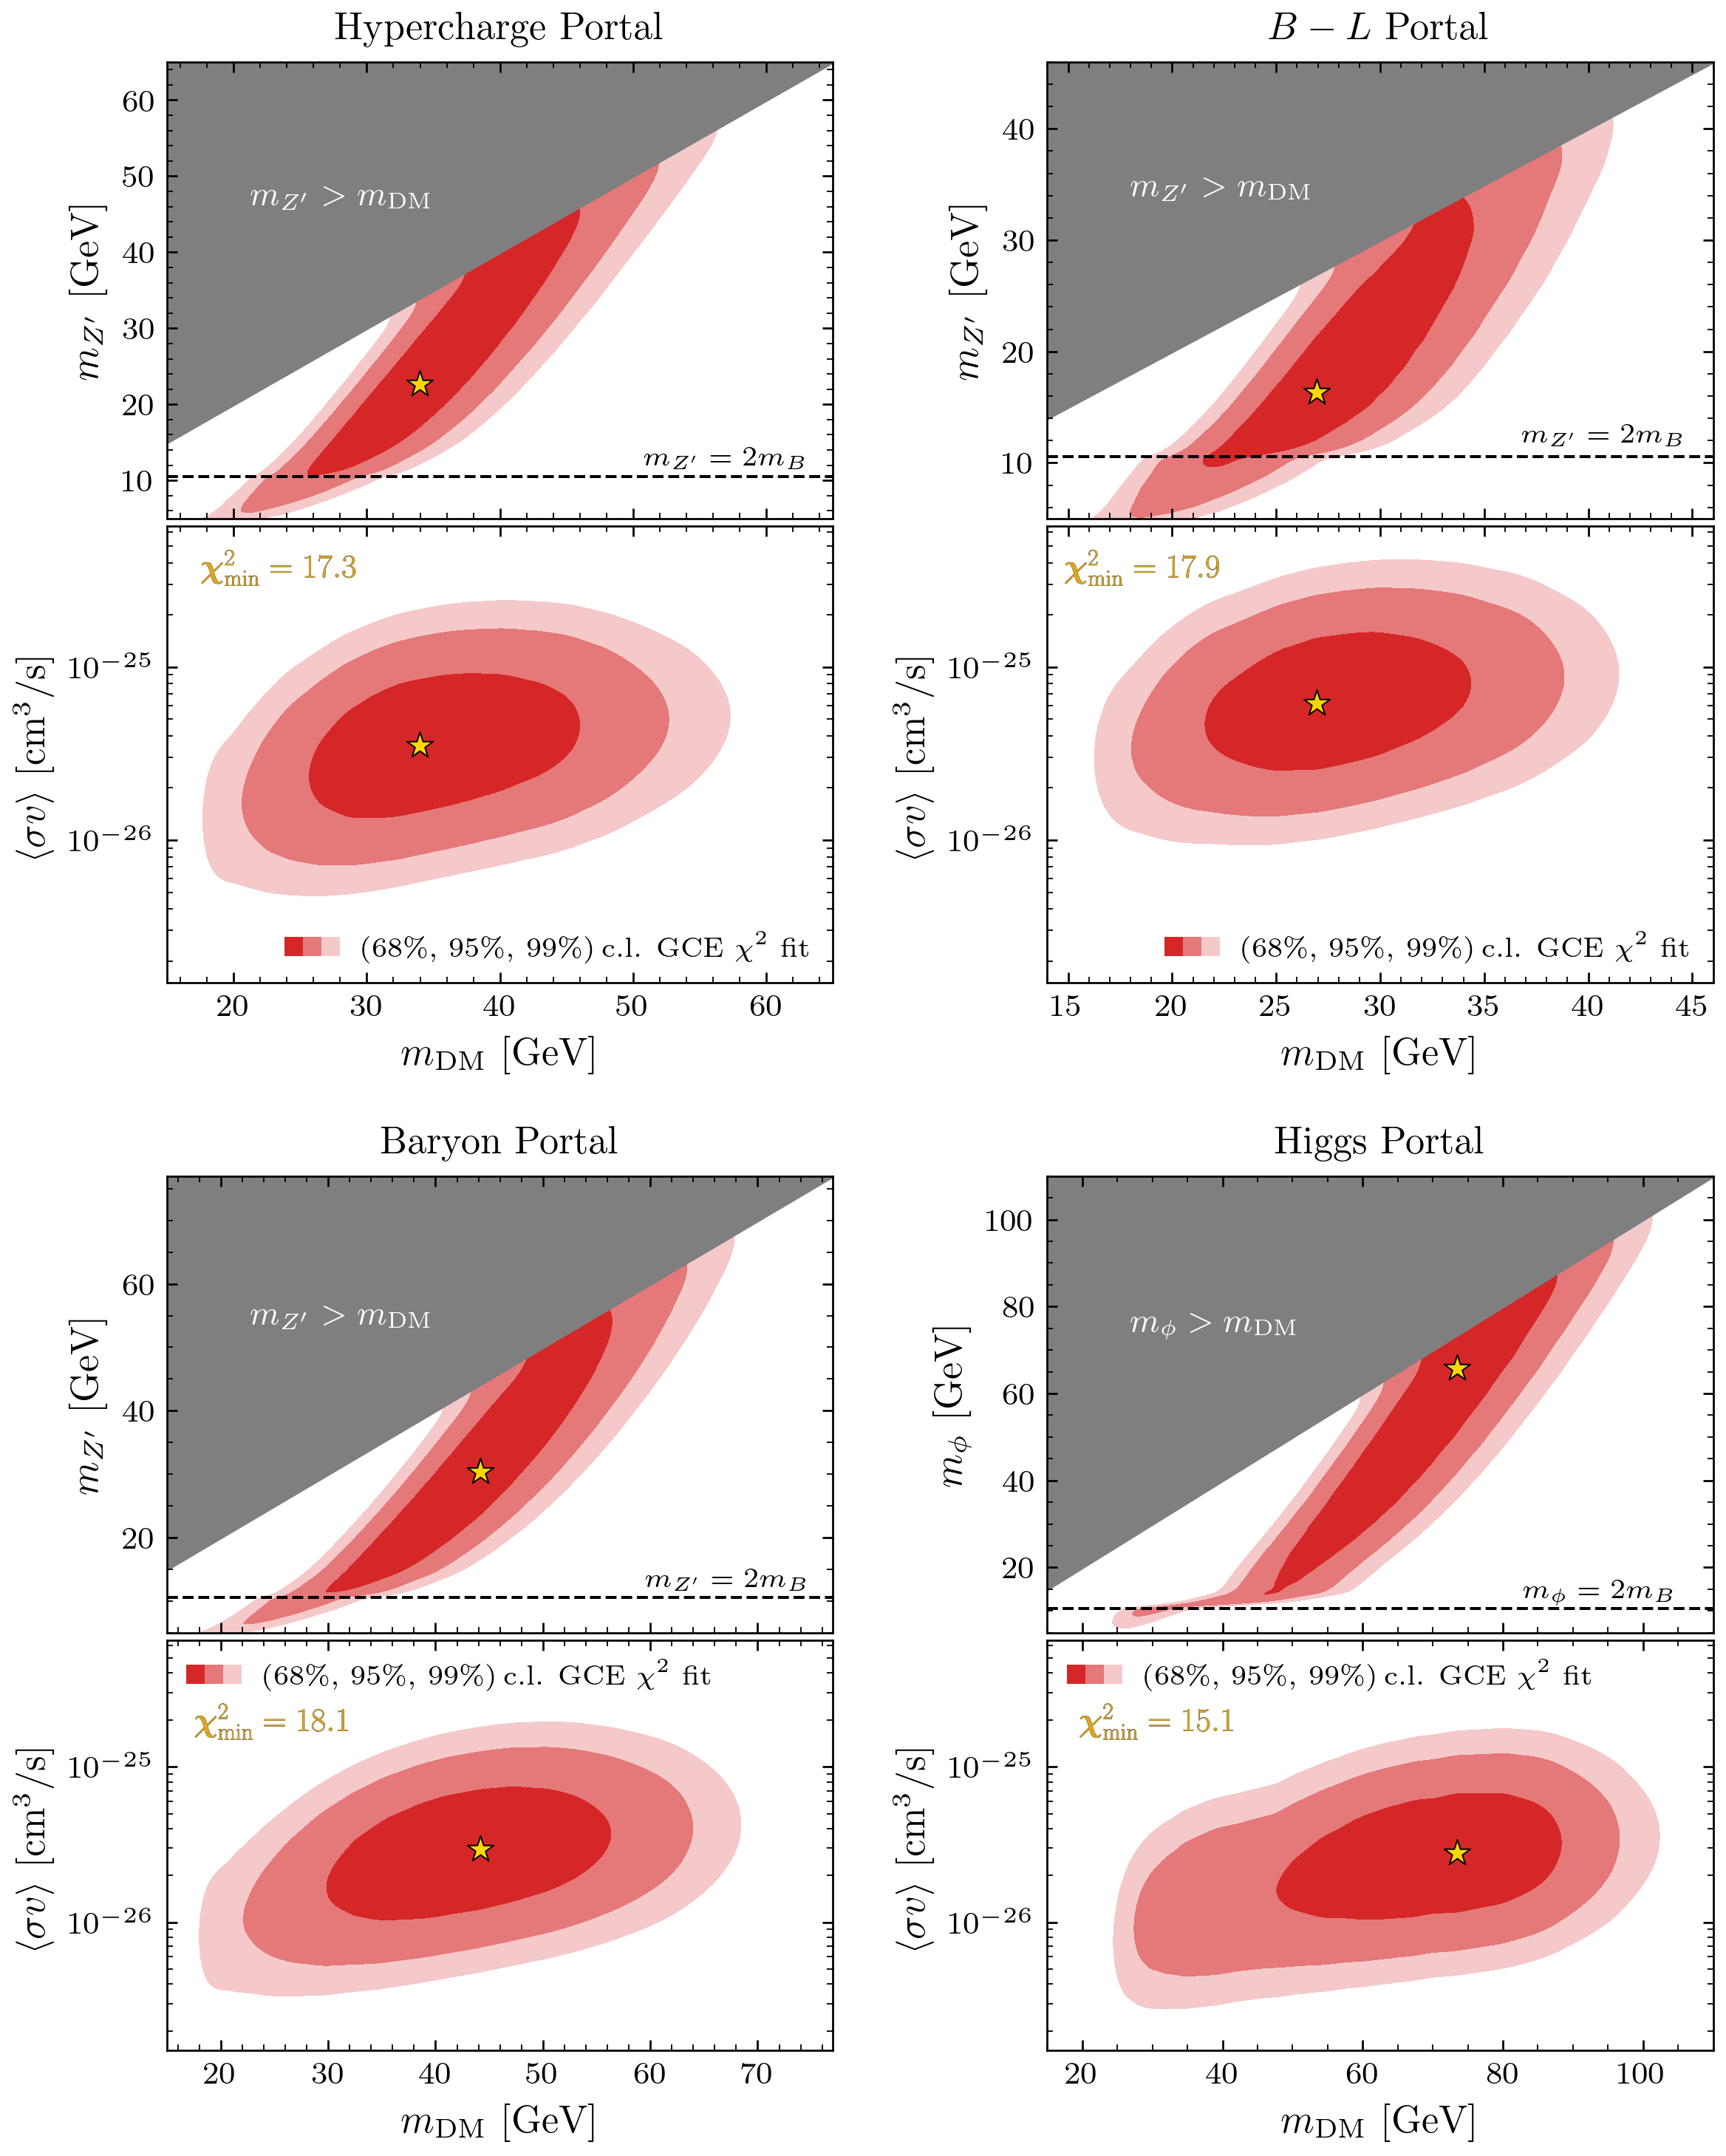

In [6]:
_GOLDEN_RATIO_=1.61803398875
cs=color_shades('tab:red', 3)
#LVs=delta_chi2(2, sigma=[0,1,2,3])
LVs=np.array([delta_chi2(2, cl=clv) for clv in np.array([0,.68,.95,.99])])
portal_axes_info={'vP':{'text':[17.5,3.3e-25,r'Hypercharge Portal'],'mxlims':[15,65],'mylims':[5,65],'leg_loc':4},
                                  'bP':{'text':[17.5,1.7e-25,r'Baryon Portal'],'mxlims':[15,77],'mylims':[5,77], 'leg_loc':2},
                                  'blP':{'text':[14.8,3.3e-25,r'$B-L$ Portal'],'mxlims':[14,46],'mylims':[5,46], 'leg_loc':4},
                                  'hP':{'text':[19.5,1.7e-25,r'Higgs Portal'],'mxlims':[15,110],'mylims':[5,110], 'leg_loc':2},
                                 }
from GCE.source.pythia_runner import HADRON_MASSES
m_thr = 2 * HADRON_MASSES["bb"]          # 2 m_B, the same value the BR cut uses
#label_names=[ 'GCE $\chi^2$ fit', r' + $\rho_{\odot}=0.44\pm 0.13\,{\rm GeV}/{\rm cm}^3$']
fig = plt.figure(figsize=(7.5, 7.5*_GOLDEN_RATIO_*0.8))

gs = GridSpec(43, 23, figure=fig)  # 7 rows and 7 columns for the triangle plot
ax11= fig.add_subplot(gs[:10, :10])
ax12= fig.add_subplot(gs[10:20, :10])
ax21= fig.add_subplot(gs[24:34, :10])
ax22= fig.add_subplot(gs[34:44, :10])
ax31= fig.add_subplot(gs[:10, 13:])
ax32= fig.add_subplot(gs[10:20, 13:])
ax41= fig.add_subplot(gs[24:34, 13:])
ax42= fig.add_subplot(gs[34:44, 13:])

axs1=[ax11,ax21,ax31,ax41]
axs2=[ax12,ax22,ax32,ax42]

mDMs=np.linspace(5,130,100)
for i in range(len(axs1)):
    axs1[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    CL1, CL2= sv_mX_mY_smooth_contours(fits[portals[i]])
    axs1[i].contourf(CL1[0],CL1[1],CL1[2], levels=LVs, colors=cs, alpha=1)
    axs2[i].contourf(CL2[0],CL2[1],CL2[2], levels=LVs,colors=cs, alpha=1)
    axs2[i].set_yscale("log")
    axs2[i].set_ylim(1.5e-27,6.5e-25)
    axs2[i].set_ylabel(r"$\langle \sigma v\rangle\,\,[{\rm cm}^3/{\rm s}]$")
    axs2[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
    if portals[i]=='hP':
        axs1[i].set_ylabel(r"$m_{\phi}\,\,[{\rm GeV}]$")
        axs1[i].text(portal_axes_info[portals[i]]['mxlims'][1]*0.95, m_thr + 0.8, r'$m_\phi = 2m_B$', fontsize=mpl.rcParams['legend.fontsize'], ha='right', va='bottom')
        axs1[i].text(portal_axes_info[portals[i]]['mxlims'][0]+(portal_axes_info[portals[i]]['mxlims'][1]-portal_axes_info[portals[i]]['mxlims'][0])/8,
          portal_axes_info[portals[i]]['mxlims'][0]+(portal_axes_info[portals[i]]['mxlims'][1]-portal_axes_info[portals[i]]['mxlims'][0])/1.6,
          r"$m_{\phi}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize']*1.2, ha='left')
    else:
        axs1[i].set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
        axs1[i].text(portal_axes_info[portals[i]]['mxlims'][1]*0.97, m_thr + 0.8, r'$m_{Z^\prime} = 2m_B$', fontsize=mpl.rcParams['legend.fontsize'], ha='right', va='bottom')
        axs1[i].text(portal_axes_info[portals[i]]['mxlims'][0]+(portal_axes_info[portals[i]]['mxlims'][1]-portal_axes_info[portals[i]]['mxlims'][0])/8,
          portal_axes_info[portals[i]]['mxlims'][0]+(portal_axes_info[portals[i]]['mxlims'][1]-portal_axes_info[portals[i]]['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize']*1.2, ha='left')
    axs1[i].scatter(float(fits[portals[i]]['mX'][fits[portals[i]]['k_best']]),
                    float(fits[portals[i]]['mY'][fits[portals[i]]['k_best']]),
                    marker='*',s=55,color='gold',linewidth=.4,edgecolor='k',zorder=10)
    axs2[i].scatter(float(fits[portals[i]]['mX'][fits[portals[i]]['k_best']]),
                    float(fits[portals[i]]['sigmav'][fits[portals[i]]['k_best']]),
                    marker='*',s=55,color='gold',linewidth=.4,edgecolor='k',zorder=10)
    axs1[i].set_title(portal_axes_info[portals[i]]['text'][2], fontsize=mpl.rcParams['axes.labelsize'])
    axs2[i].text(portal_axes_info[portals[i]]['text'][0],portal_axes_info[portals[i]]['text'][1],
                 rf"$\bm \chi^2_{{\rm min}}={float(fits[portals[i]]['chi2'][fits[portals[i]]['k_best']]):.1f}$",
                 color='goldenrod', path_effects=[pe.withStroke(linewidth=0.10, foreground='black')],
                 fontsize=1.2*mpl.rcParams['legend.fontsize'], ha='left')
    axs2[i].legend(
    handles=[(Patch(facecolor=cs[0]),Patch(facecolor=cs[1]),Patch(facecolor=cs[2]))],
    #labels=[r'$(1\sigma,\,2\sigma,\,3\sigma)$ GCE $\chi^2$ fit'],
    labels=[r'$(68\%,\,95\%,\,99\%)\,$c.l. GCE $\chi^2$ fit'],
    loc=portal_axes_info[portals[i]]['leg_loc'],
    fontsize=mpl.rcParams['legend.fontsize'],
    handler_map={tuple: mpl.legend_handler.HandlerTuple(ndivide=None, pad=0.0)},
    )
    axs2[i].set_xlim(portal_axes_info[portals[i]]['mxlims'][0],portal_axes_info[portals[i]]['mxlims'][1])
    axs1[i].set_xlim(portal_axes_info[portals[i]]['mxlims'][0],portal_axes_info[portals[i]]['mxlims'][1])

    axs1[i].set_xticklabels([])
    axs1[i].set_ylim(portal_axes_info[portals[i]]['mylims'][0],portal_axes_info[portals[i]]['mylims'][1])
    axs1[i].axhline(m_thr, c='k', ls='--', lw=0.8, zorder=3)
plt.savefig("../paper_figs/GCE_fits_v0.png")
plt.savefig("../paper_figs/GCE_fits_v0.pdf")
plt.show()
plt.close()

## Regions with the observed relic abundance
The GCE region when $\langle\sigma v\rangle$ is fixed by $\Omega_c h^2 = 0.12$: thermalised ($\epsilon \geq \epsilon_{\rm therm}$), joint solver at $\epsilon = 10^{-9}, 10^{-10}$, and secluded at $\epsilon = 10^{-11}$, with $\rho_\odot$ profiled. One figure per portal.

In [7]:
# ---- relic <sigma v> below the thermalisation floor, eps < eps_therm ------
# Coarse (log10 mX, log10 rv) grids from GCE/scripts/make_relic_grid.py, in
# SV_RELIC_DIR.  Each joint eps has its own file; the secluded eps share one
# (one freeze-out, two dilutions) with eps as the leading axis.
EPS_JOINT    = (1e-9, 1e-10)
EPS_SECLUDED = (1e-11, 1e-12)

EPS_JOINT_hP    = (1e-7, 1e-8)
EPS_SECLUDED_hP = (1e-9, 1e-10)

# s-wave <sigma v>(mX, mY, coupling) in closed form; it vectorises, so no model per
# grid point.  vP, bP and blP share the hidden sector, so all three call the
# vector-portal form in alpha_X; the hP grid's coupling is lam, which sets lam_s = lam_p
SV_SWAVE = {'vP':  VectorPortal._sigmav_XX_to_YY_swave,
            'bP':  VectorPortal._sigmav_XX_to_YY_swave,
            'blP': VectorPortal._sigmav_XX_to_YY_swave,
            'hP':  lambda mX, mY, lam: HiggsPortal._sigmav_XX_to_YY_swave(mX, mY, lam, lam)}

def coupling_relic_at_eps(name, eps, xi_ini=1.0):
    """Coupling (alpha_X, or lam for hP) for Omega_c h^2 = 0.12 at `eps`, interpolated
    in log10 from the coarse grid onto the portal's own grid; NaN outside the coarse
    hull (rv > 0.95, and mX > 128.78 for the hP extension, whose coarse mesh stops one
    column short of the fit grid).  `xi_ini` != 1 reads that T_D/T_SM variant (vP only)."""
    mX_grid, mY_grid = portal_grid(name)
    tag = name if xi_ini == 1.0 else f'{name}_xi_ini_{xi_ini:g}'
    if eps in (EPS_SECLUDED_hP if name == 'hP' else EPS_SECLUDED):
        relic = np.load(SV_RELIC_DIR / f'relic_grid_{tag}_eps_secluded.npz')
        # exact equality: np.isclose's default atol=1e-8 exceeds every eps here
        coupling_c = relic['coupling_relic'][int(np.flatnonzero(relic['eps'] == eps)[0])]
    else:
        relic = np.load(SV_RELIC_DIR / f'relic_grid_{tag}_eps{eps:.0e}.npz')
        coupling_c = relic['coupling_relic']
    n_domain = int(np.isfinite(relic['mX_grid']).sum())
    if int(relic['n_done']) < n_domain:
        print(f"WARNING {tag} eps={eps:.0e}: only {int(relic['n_done'])}/{n_domain} coarse nodes done")

    # keep only nodes whose coupling is an interpolated (not extrapolated) read
    # of the sampled Omega h^2(coupling) curve
    axis = relic['coupling_axis']
    ok_c = np.isfinite(coupling_c) & (coupling_c >= axis.min()) & (coupling_c <= axis.max())
    lmx_c, lrv_c = np.meshgrid(relic['log_mX'], relic['log_rv'], indexing='ij')
    return 10.0 ** griddata(np.column_stack([lmx_c[ok_c], lrv_c[ok_c]]), np.log10(coupling_c[ok_c]),
                            np.column_stack([np.log10(mX_grid), np.log10(mY_grid / mX_grid)]),
                            method='linear')

def sv_relic_at_eps(name, eps, xi_ini=1.0):
    mX_grid, mY_grid = portal_grid(name)
    coupling = coupling_relic_at_eps(name, eps, xi_ini)
    ok = np.isfinite(coupling)
    sv_relic = np.full(mX_grid.size, np.nan)
    sv_relic[ok] = SV_SWAVE[name](mX_grid[ok], mY_grid[ok], coupling[ok]) * GEVM2_TO_CM3S
    # carried along so the contour helpers need the dict alone, not the portal name
    return {'mX': mX_grid, 'mY': mY_grid,
            'coupling_relic': coupling, 'sigmav_relic': sv_relic}

fits_relic_eps = {}
for name in portals:
    if name=='hP':
        fits_relic_eps[name]={eps: sv_relic_at_eps(name, eps) for eps in EPS_JOINT_hP + EPS_SECLUDED_hP}
    else:
        fits_relic_eps[name]={eps: sv_relic_at_eps(name, eps) for eps in EPS_JOINT + EPS_SECLUDED}

for name, by_eps in fits_relic_eps.items():
    for eps, relic in by_eps.items():
        relic['dchi2_fixed_halo'], relic['dchi2_profiled'] = sv_relic_region(relic, fits[name])
        print(f"{name:4s} eps={eps:.0e}: {np.isfinite(relic['sigmav_relic']).sum():5d} points, "
              f"min dchi2 = {np.nanmin(relic['dchi2_fixed_halo']):.2f} (rho fixed), "
              f"{np.nanmin(relic['dchi2_profiled']):.2f} (rho profiled)")

vP   eps=1e-09: 15759 points, min dchi2 = 35.92 (rho fixed), 8.00 (rho profiled)
vP   eps=1e-10: 15759 points, min dchi2 = 13.97 (rho fixed), 2.74 (rho profiled)
vP   eps=1e-11: 15759 points, min dchi2 = 0.17 (rho fixed), 0.10 (rho profiled)


vP   eps=1e-12: 15759 points, min dchi2 = 2.20 (rho fixed), 0.90 (rho profiled)
bP   eps=1e-09: 15759 points, min dchi2 = 152.28 (rho fixed), 6.67 (rho profiled)
bP   eps=1e-10: 15759 points, min dchi2 = 49.64 (rho fixed), 5.29 (rho profiled)


bP   eps=1e-11: 15759 points, min dchi2 = 0.05 (rho fixed), 0.05 (rho profiled)
bP   eps=1e-12: 15759 points, min dchi2 = 1.90 (rho fixed), 0.94 (rho profiled)
blP  eps=1e-09: 15759 points, min dchi2 = 0.81 (rho fixed), 0.55 (rho profiled)


blP  eps=1e-10: 15759 points, min dchi2 = 20.32 (rho fixed), 3.09 (rho profiled)
blP  eps=1e-11: 15759 points, min dchi2 = 0.07 (rho fixed), 0.00 (rho profiled)
blP  eps=1e-12: 15759 points, min dchi2 = 1.34 (rho fixed), 1.34 (rho profiled)


hP   eps=1e-07: 16239 points, min dchi2 = 141.62 (rho fixed), 3.65 (rho profiled)
hP   eps=1e-08: 16236 points, min dchi2 = 124.36 (rho fixed), 5.18 (rho profiled)
hP   eps=1e-09: 16239 points, min dchi2 = 0.88 (rho fixed), 0.78 (rho profiled)


hP   eps=1e-10: 16239 points, min dchi2 = 1.58 (rho fixed), 0.23 (rho profiled)


In [8]:
def relic_mX_mY_smooth_contours(relic, SIGMA=2.5, DM_halo_profiled=True):
    if DM_halo_profiled:
        dchi2 = relic['dchi2_profiled']
    else:
        dchi2=relic['dchi2_fixed_halo']
    fin = np.isfinite(dchi2)
    mXmY_contour = smoothed_field(relic['mX'][fin], relic['mY'][fin], dchi2[fin], sigma=SIGMA, rezero=False)
    return mXmY_contour

/tmp/ipykernel_3588566/757679762.py:26: RuntimeWarning: divide by zero encountered in log10
  log_sv = smoothed_field(fit['mX'][fin], fit['mY'][fin], np.log10(fit['sigmav_relic'][fin]),


/home/gab/Desktop/Cosmo_Codes/cosmo_env/lib/python3.9/site-packages/matplotlib/tri/_triinterpolate.py:277: RuntimeWarning: invalid value encountered in add
  return (self._plane_coefficients[tri_index, 0]*x +


  0%|          | 0/4 [00:00<?, ?it/s]

 50%|█████     | 2/4 [00:00<00:00, 15.71it/s]

100%|██████████| 4/4 [00:00<00:00, 15.59it/s]

100%|██████████| 4/4 [00:00<00:00, 15.57it/s]

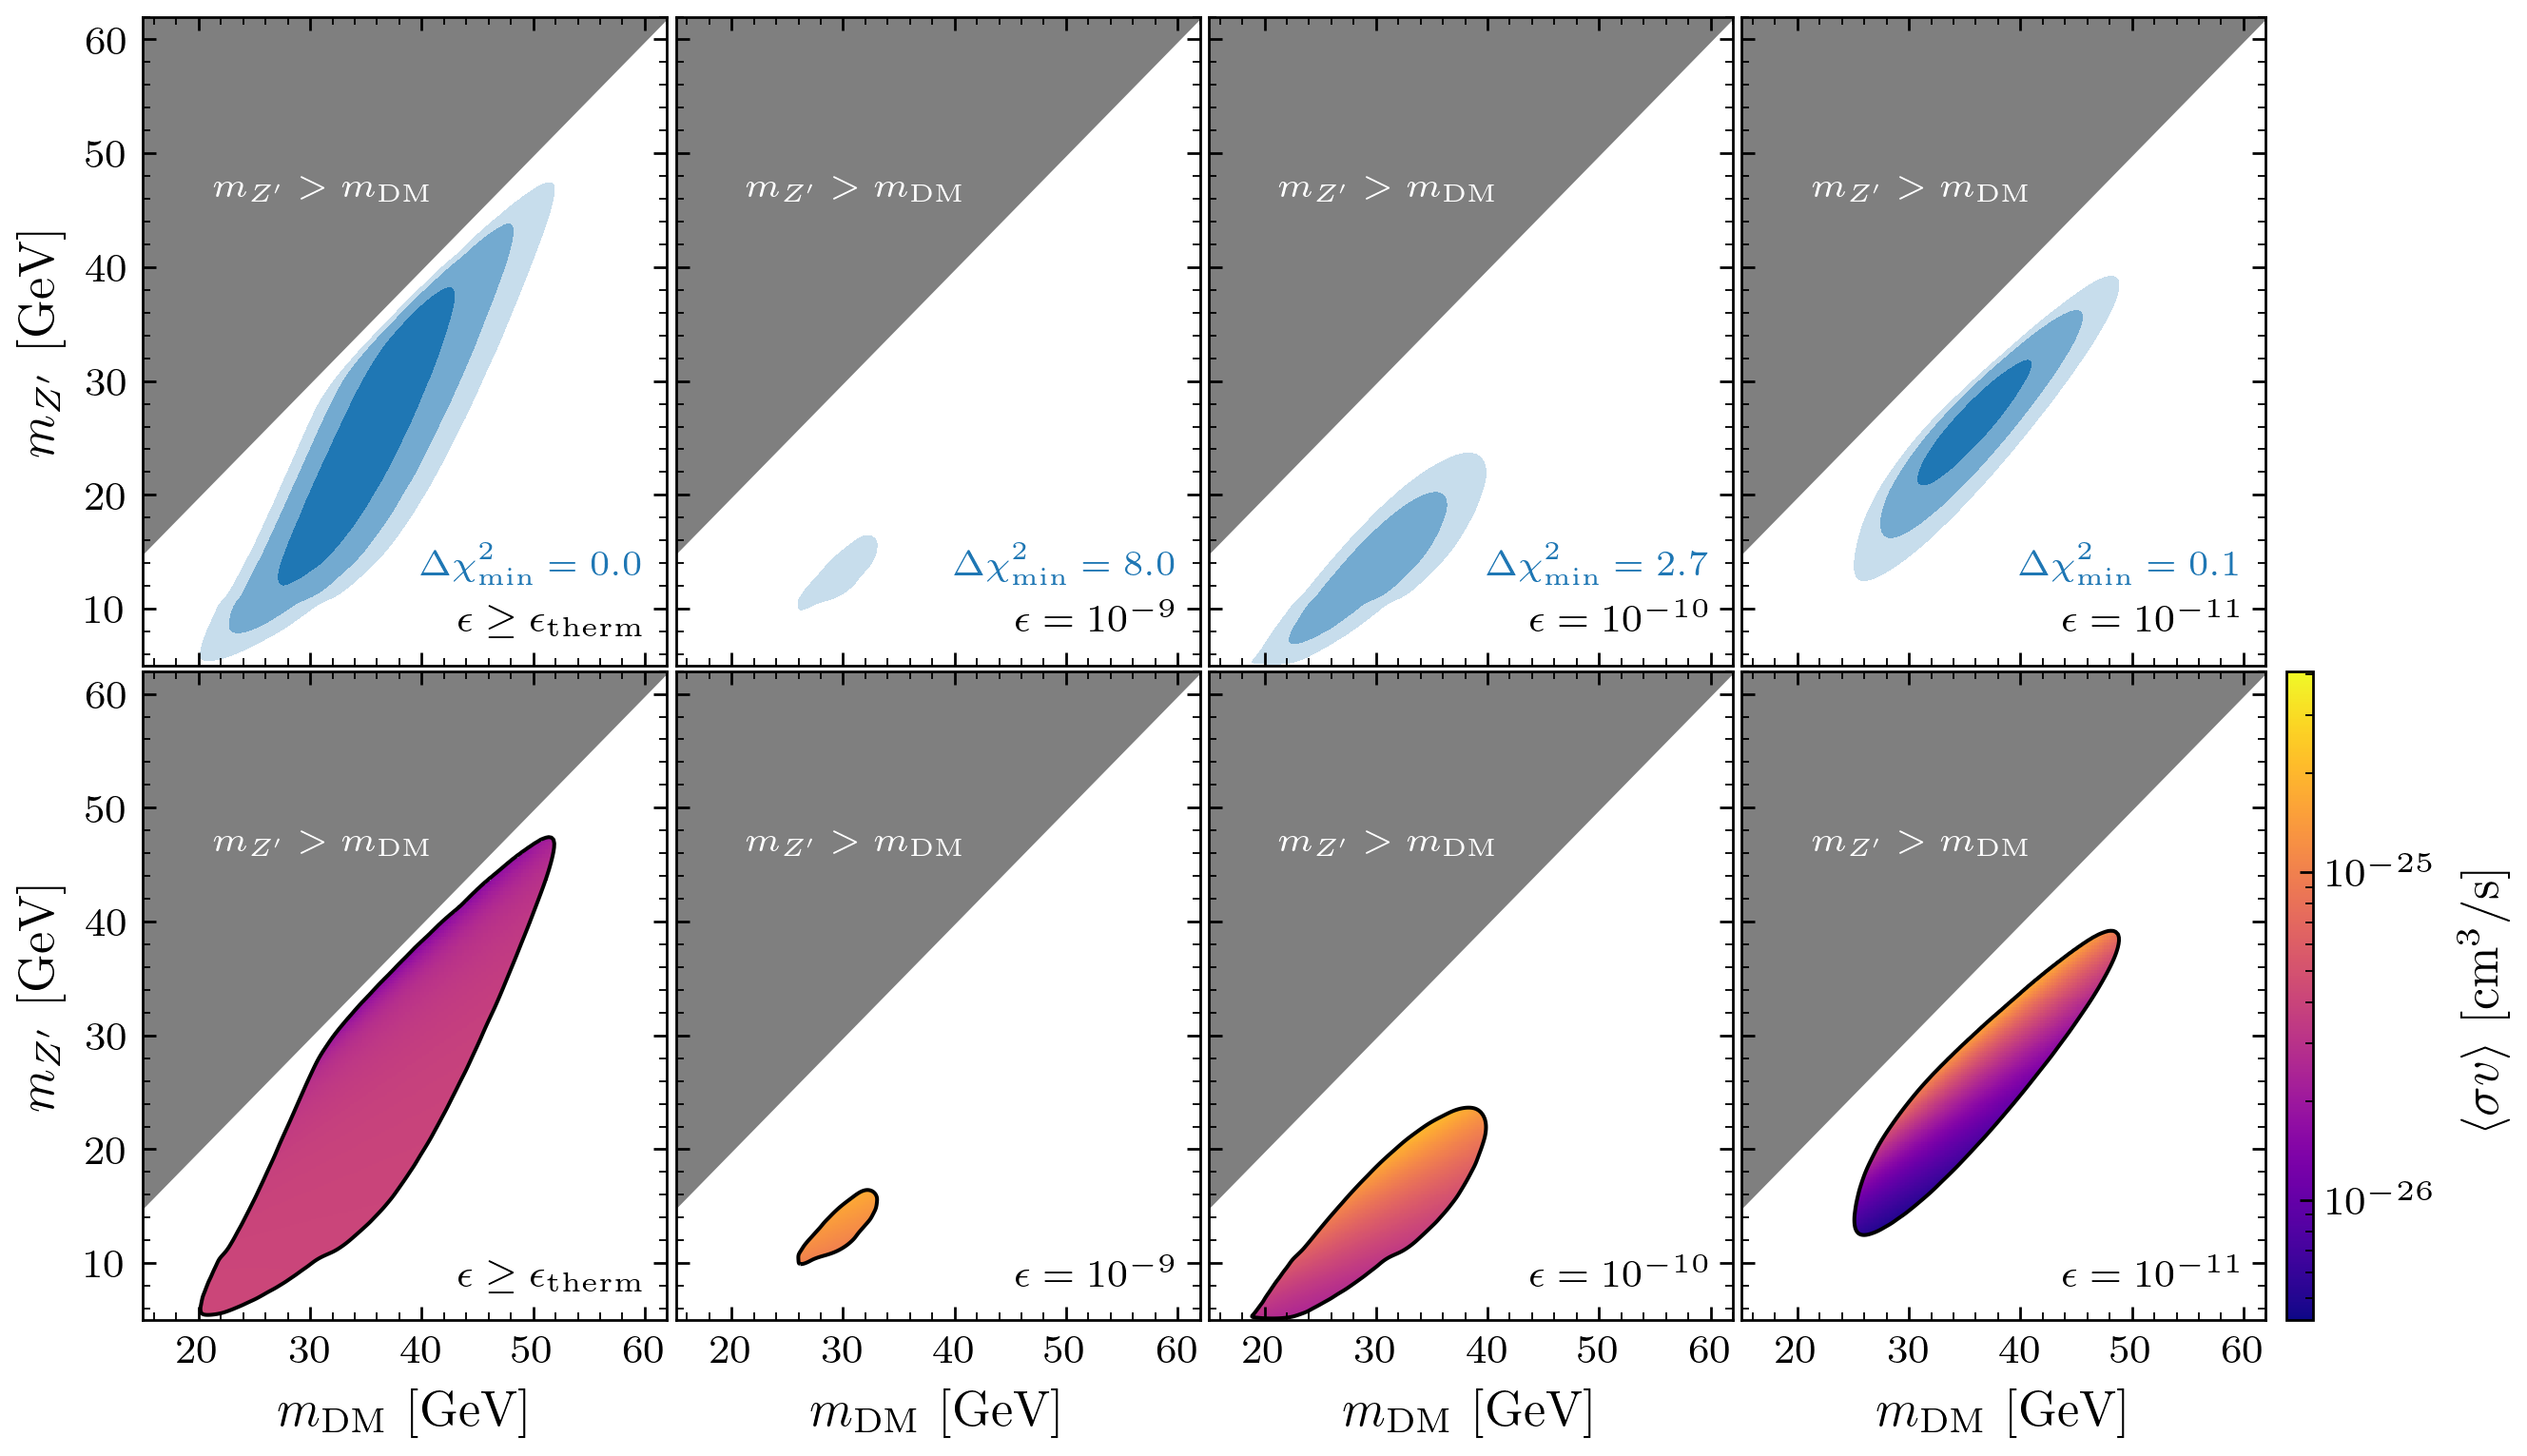

In [9]:
vP_fits=[fits_relic['vP'], fits_relic_eps['vP'][1e-9], fits_relic_eps['vP'][1e-10], fits_relic_eps['vP'][1e-11]]
cs1 = color_shades('tab:blue', 3)
eps_tex= [r'$\epsilon\geq \epsilon_{\rm therm}$',
          r'$\epsilon=10^{-9}$',
          r'$\epsilon=10^{-10}$',
          r'$\epsilon=10^{-11}$'
         ]
fig= plt.figure(figsize=(8, 8/(_GOLDEN_RATIO_)))
mDMs = np.linspace(5, 80, 100)
gs = GridSpec(40, 40, figure=fig)  # 7 rows and 7 columns for the triangle plot
ax1= fig.add_subplot(gs[:20, :10])
ax2= fig.add_subplot(gs[:20,10:20])
ax3= fig.add_subplot(gs[:20,20:30])
ax4= fig.add_subplot(gs[:20,30:])
ax12= fig.add_subplot(gs[20:, :10])
ax22= fig.add_subplot(gs[20:,10:20])
ax32= fig.add_subplot(gs[20:,20:30])
ax42= fig.add_subplot(gs[20:,30:])
axs=[ax1,ax2,ax3,ax4]
axs2=[ax12,ax22,ax32,ax42]
# relic <sigma v> inside each panel's 99% c.l. region; one colour scale, fixed across the vP, bP, blP figures
CLs = [relic_mX_mY_smooth_contours(fit, SIGMA=3) for fit in vP_fits]
log_svs = []
for fit, CL in zip(vP_fits, CLs):
    fin = np.isfinite(fit['dchi2_profiled'])     # the points CL was built from, so the same mesh
    log_sv = smoothed_field(fit['mX'][fin], fit['mY'][fin], np.log10(fit['sigmav_relic'][fin]),
                            sigma=3, rezero=False)[2]
    log_svs.append(np.where(CL[2] <= LVs[3], log_sv, np.nan))
for i in trange(len(axs)):
    axs[i].set_xlim(15,62)
    axs[i].set_xticks([20,30,40,50,60])
    axs[i].set_xticklabels([])
    axs2[i].set_xlim(15,62)
    axs2[i].set_xticks([20,30,40,50,60])
    axs[i].set_ylim(5, 62)
    axs[i].set_yticks([10,20,30,40,50,60])
    axs2[i].set_ylim(5, 62)
    axs2[i].set_yticks([10,20,30,40,50,60])
    if i!=0:
        axs[i].set_yticklabels([])
        axs2[i].set_yticklabels([])
    CL1=CLs[i]
    axs[i].contourf(CL1[0],CL1[1],CL1[2], levels=LVs, colors=cs1, zorder=1.5)
    cf_sv = axs2[i].pcolormesh(CL1[0],CL1[1],10**log_svs[i], cmap='plasma', shading='auto', zorder=1.5,
                               norm=mcolors.LogNorm(vmin=4.3e-27, vmax=4.1e-25),  # min / max over the vP, bP, blP 99% regions
                               rasterized=True)
    axs2[i].contour(CL1[0],CL1[1],CL1[2], levels=[LVs[3]], colors='k', linewidths=0.8, zorder=1.6)
    axs[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs2[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs[i].text(portal_axes_info['vP']['mxlims'][0]+(portal_axes_info['vP']['mxlims'][1]-portal_axes_info['vP']['mxlims'][0])/8,
          portal_axes_info['vP']['mxlims'][0]+(portal_axes_info['vP']['mxlims'][1]-portal_axes_info['vP']['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs2[i].text(portal_axes_info['vP']['mxlims'][0]+(portal_axes_info['vP']['mxlims'][1]-portal_axes_info['vP']['mxlims'][0])/8,
          portal_axes_info['vP']['mxlims'][0]+(portal_axes_info['vP']['mxlims'][1]-portal_axes_info['vP']['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs[i].text(60,8,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs2[i].text(60,8,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs[i].text(60,13, 
                rf"$\Delta \chi^2_{{\rm min}}={np.nanmin(vP_fits[i]['dchi2_profiled']):.1f}$", 
                color=cs1[0], fontsize=mpl.rcParams['legend.fontsize'], ha='right')
    
    axs2[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
ax1.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
ax12.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
cbar = fig.colorbar(cf_sv, cax=ax42.inset_axes([1.04, 0.0, 0.05, 1.0]),
                    label=r"$\langle\sigma v\rangle\,\,[{\rm cm}^3/{\rm s}]$")
cbar.set_ticks([1e-26, 1e-25])                                                   # labelled decades
cbar.ax.yaxis.set_minor_locator(mpl.ticker.LogLocator(subs=np.arange(2, 10)))   # 2..9 x 10^n
cbar.ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
#ax2.text(32,64,r"Hypercharge Portal "+ rf"($\chi^2_{{\rm min}}={float(fits['vP']['chi2'][fits['vP']['k_best']]):.1f}$)",  fontsize=mpl.rcParams['axes.labelsize'], ha='left')
plt.savefig("../paper_figs/GCE_fits_vP_secluded_v0.png")
plt.savefig("../paper_figs/GCE_fits_vP_secluded_v0.pdf")
plt.show()
plt.close()

/tmp/ipykernel_3588566/1232243828.py:26: RuntimeWarning: divide by zero encountered in log10
  log_sv = smoothed_field(fit['mX'][fin], fit['mY'][fin], np.log10(fit['sigmav_relic'][fin]),


/home/gab/Desktop/Cosmo_Codes/cosmo_env/lib/python3.9/site-packages/matplotlib/tri/_triinterpolate.py:277: RuntimeWarning: invalid value encountered in add
  return (self._plane_coefficients[tri_index, 0]*x +


  0%|          | 0/4 [00:00<?, ?it/s]

 50%|█████     | 2/4 [00:00<00:00, 14.85it/s]

100%|██████████| 4/4 [00:00<00:00, 14.88it/s]

100%|██████████| 4/4 [00:00<00:00, 14.84it/s]

18.101194160010188


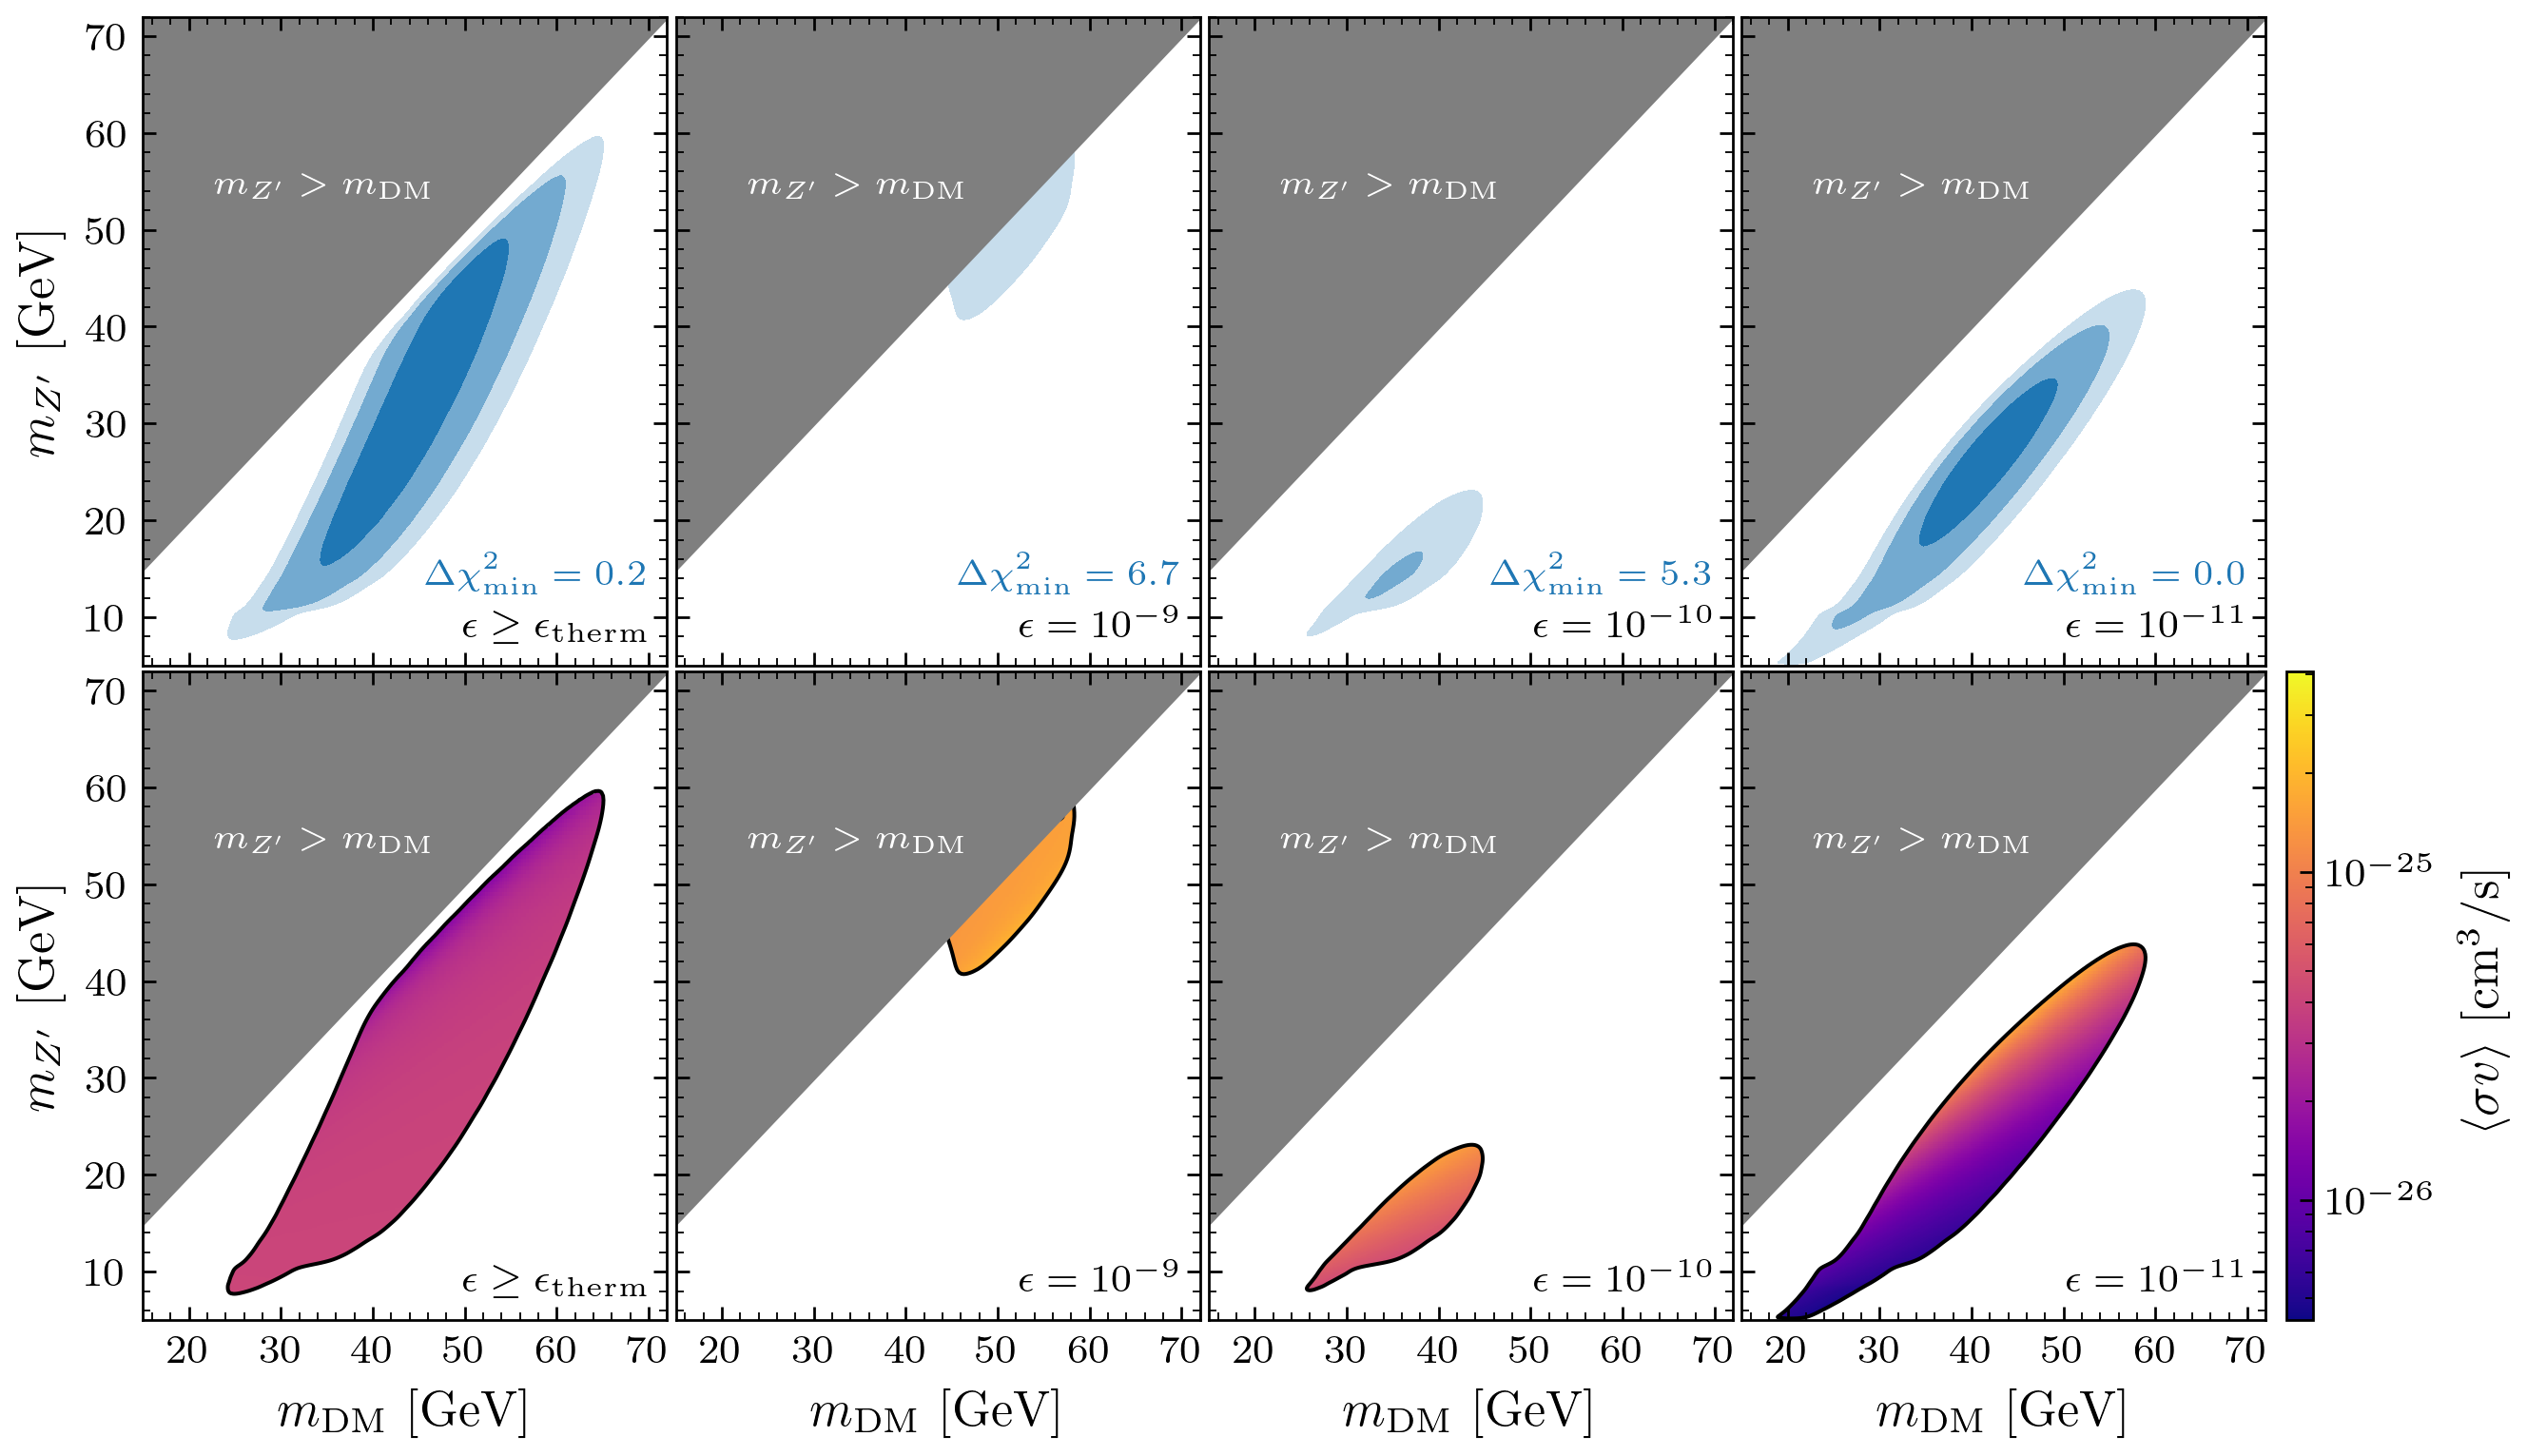

In [10]:
bP_fits=[fits_relic['bP'], fits_relic_eps['bP'][1e-9], fits_relic_eps['bP'][1e-10], fits_relic_eps['bP'][1e-11]]
cs1 = color_shades('tab:blue', 3)
eps_tex= [r'$\epsilon\geq \epsilon_{\rm therm}$',
          r'$\epsilon=10^{-9}$',
          r'$\epsilon=10^{-10}$',
          r'$\epsilon=10^{-11}$'
         ]
fig= plt.figure(figsize=(8, 8/(_GOLDEN_RATIO_)))
mDMs = np.linspace(5, 80, 100)
gs = GridSpec(40, 40, figure=fig)  # 7 rows and 7 columns for the triangle plot
ax1= fig.add_subplot(gs[:20, :10])
ax2= fig.add_subplot(gs[:20,10:20])
ax3= fig.add_subplot(gs[:20,20:30])
ax4= fig.add_subplot(gs[:20,30:])
ax12= fig.add_subplot(gs[20:, :10])
ax22= fig.add_subplot(gs[20:,10:20])
ax32= fig.add_subplot(gs[20:,20:30])
ax42= fig.add_subplot(gs[20:,30:])
axs=[ax1,ax2,ax3,ax4]
axs2=[ax12,ax22,ax32,ax42]
# relic <sigma v> inside each panel's 99% c.l. region; one colour scale, fixed across the vP, bP, blP figures
CLs = [relic_mX_mY_smooth_contours(fit, SIGMA=3) for fit in bP_fits]
log_svs = []
for fit, CL in zip(bP_fits, CLs):
    fin = np.isfinite(fit['dchi2_profiled'])     # the points CL was built from, so the same mesh
    log_sv = smoothed_field(fit['mX'][fin], fit['mY'][fin], np.log10(fit['sigmav_relic'][fin]),
                            sigma=3, rezero=False)[2]
    log_svs.append(np.where(CL[2] <= LVs[3], log_sv, np.nan))
for i in trange(len(axs)):
    axs[i].set_xlim(15,72)
    axs[i].set_xticks([20,30,40,50,60,70])
    axs[i].set_xticklabels([])
    axs2[i].set_xlim(15,72)
    axs2[i].set_xticks([20,30,40,50,60,70])
    axs[i].set_ylim(5, 72)
    axs[i].set_yticks([10,20,30,40,50,60,70])
    axs2[i].set_ylim(5, 72)
    axs2[i].set_yticks([10,20,30,40,50,60,70])
    if i!=0:
        axs[i].set_yticklabels([])
        axs2[i].set_yticklabels([])
    CL1=CLs[i]
    axs[i].contourf(CL1[0],CL1[1],CL1[2], levels=LVs, colors=cs1, zorder=1.5)
    cf_sv = axs2[i].pcolormesh(CL1[0],CL1[1],10**log_svs[i], cmap='plasma', shading='auto', zorder=1.5,
                               norm=mcolors.LogNorm(vmin=4.3e-27, vmax=4.1e-25),  # min / max over the vP, bP, blP 99% regions
                               rasterized=True)
    axs2[i].contour(CL1[0],CL1[1],CL1[2], levels=[LVs[3]], colors='k', linewidths=0.8, zorder=1.6)
    axs[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs2[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs[i].text(portal_axes_info['bP']['mxlims'][0]+(portal_axes_info['bP']['mxlims'][1]-portal_axes_info['bP']['mxlims'][0])/8,
          portal_axes_info['bP']['mxlims'][0]+(portal_axes_info['bP']['mxlims'][1]-portal_axes_info['bP']['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs2[i].text(portal_axes_info['bP']['mxlims'][0]+(portal_axes_info['bP']['mxlims'][1]-portal_axes_info['bP']['mxlims'][0])/8,
          portal_axes_info['bP']['mxlims'][0]+(portal_axes_info['bP']['mxlims'][1]-portal_axes_info['bP']['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs[i].text(70,8,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs2[i].text(70,8,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs[i].text(70,13.5, rf"$\Delta \chi^2_{{\rm min}}={np.nanmin(bP_fits[i]['dchi2_profiled']):.1f}$",  color=cs1[0], fontsize=mpl.rcParams['legend.fontsize'], ha='right')
    axs2[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
ax1.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
ax12.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
cbar = fig.colorbar(cf_sv, cax=ax42.inset_axes([1.04, 0.0, 0.05, 1.0]),
                    label=r"$\langle\sigma v\rangle\,\,[{\rm cm}^3/{\rm s}]$")
cbar.set_ticks([1e-26, 1e-25])                                                   # labelled decades
cbar.ax.yaxis.set_minor_locator(mpl.ticker.LogLocator(subs=np.arange(2, 10)))   # 2..9 x 10^n
cbar.ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
#ax2.text(42,75, r"Baryon Portal "+ rf"($\chi^2_{{\rm min}}={float(fits['bP']['chi2'][fits['bP']['k_best']]):.1f}$)",  fontsize=mpl.rcParams['axes.labelsize'], ha='left')
plt.savefig("../paper_figs/GCE_fits_bP_secluded_v0.png")
plt.savefig("../paper_figs/GCE_fits_bP_secluded_v0.pdf")
print(float(fits['bP']['chi2'][fits['bP']['k_best']]))
plt.show()
plt.close()

/tmp/ipykernel_3588566/1149914000.py:26: RuntimeWarning: divide by zero encountered in log10
  log_sv = smoothed_field(fit['mX'][fin], fit['mY'][fin], np.log10(fit['sigmav_relic'][fin]),


/home/gab/Desktop/Cosmo_Codes/cosmo_env/lib/python3.9/site-packages/matplotlib/tri/_triinterpolate.py:277: RuntimeWarning: invalid value encountered in add
  return (self._plane_coefficients[tri_index, 0]*x +


  0%|          | 0/4 [00:00<?, ?it/s]

 50%|█████     | 2/4 [00:00<00:00, 17.14it/s]

100%|██████████| 4/4 [00:00<00:00, 17.25it/s]

100%|██████████| 4/4 [00:00<00:00, 17.14it/s]

17.88814615035161


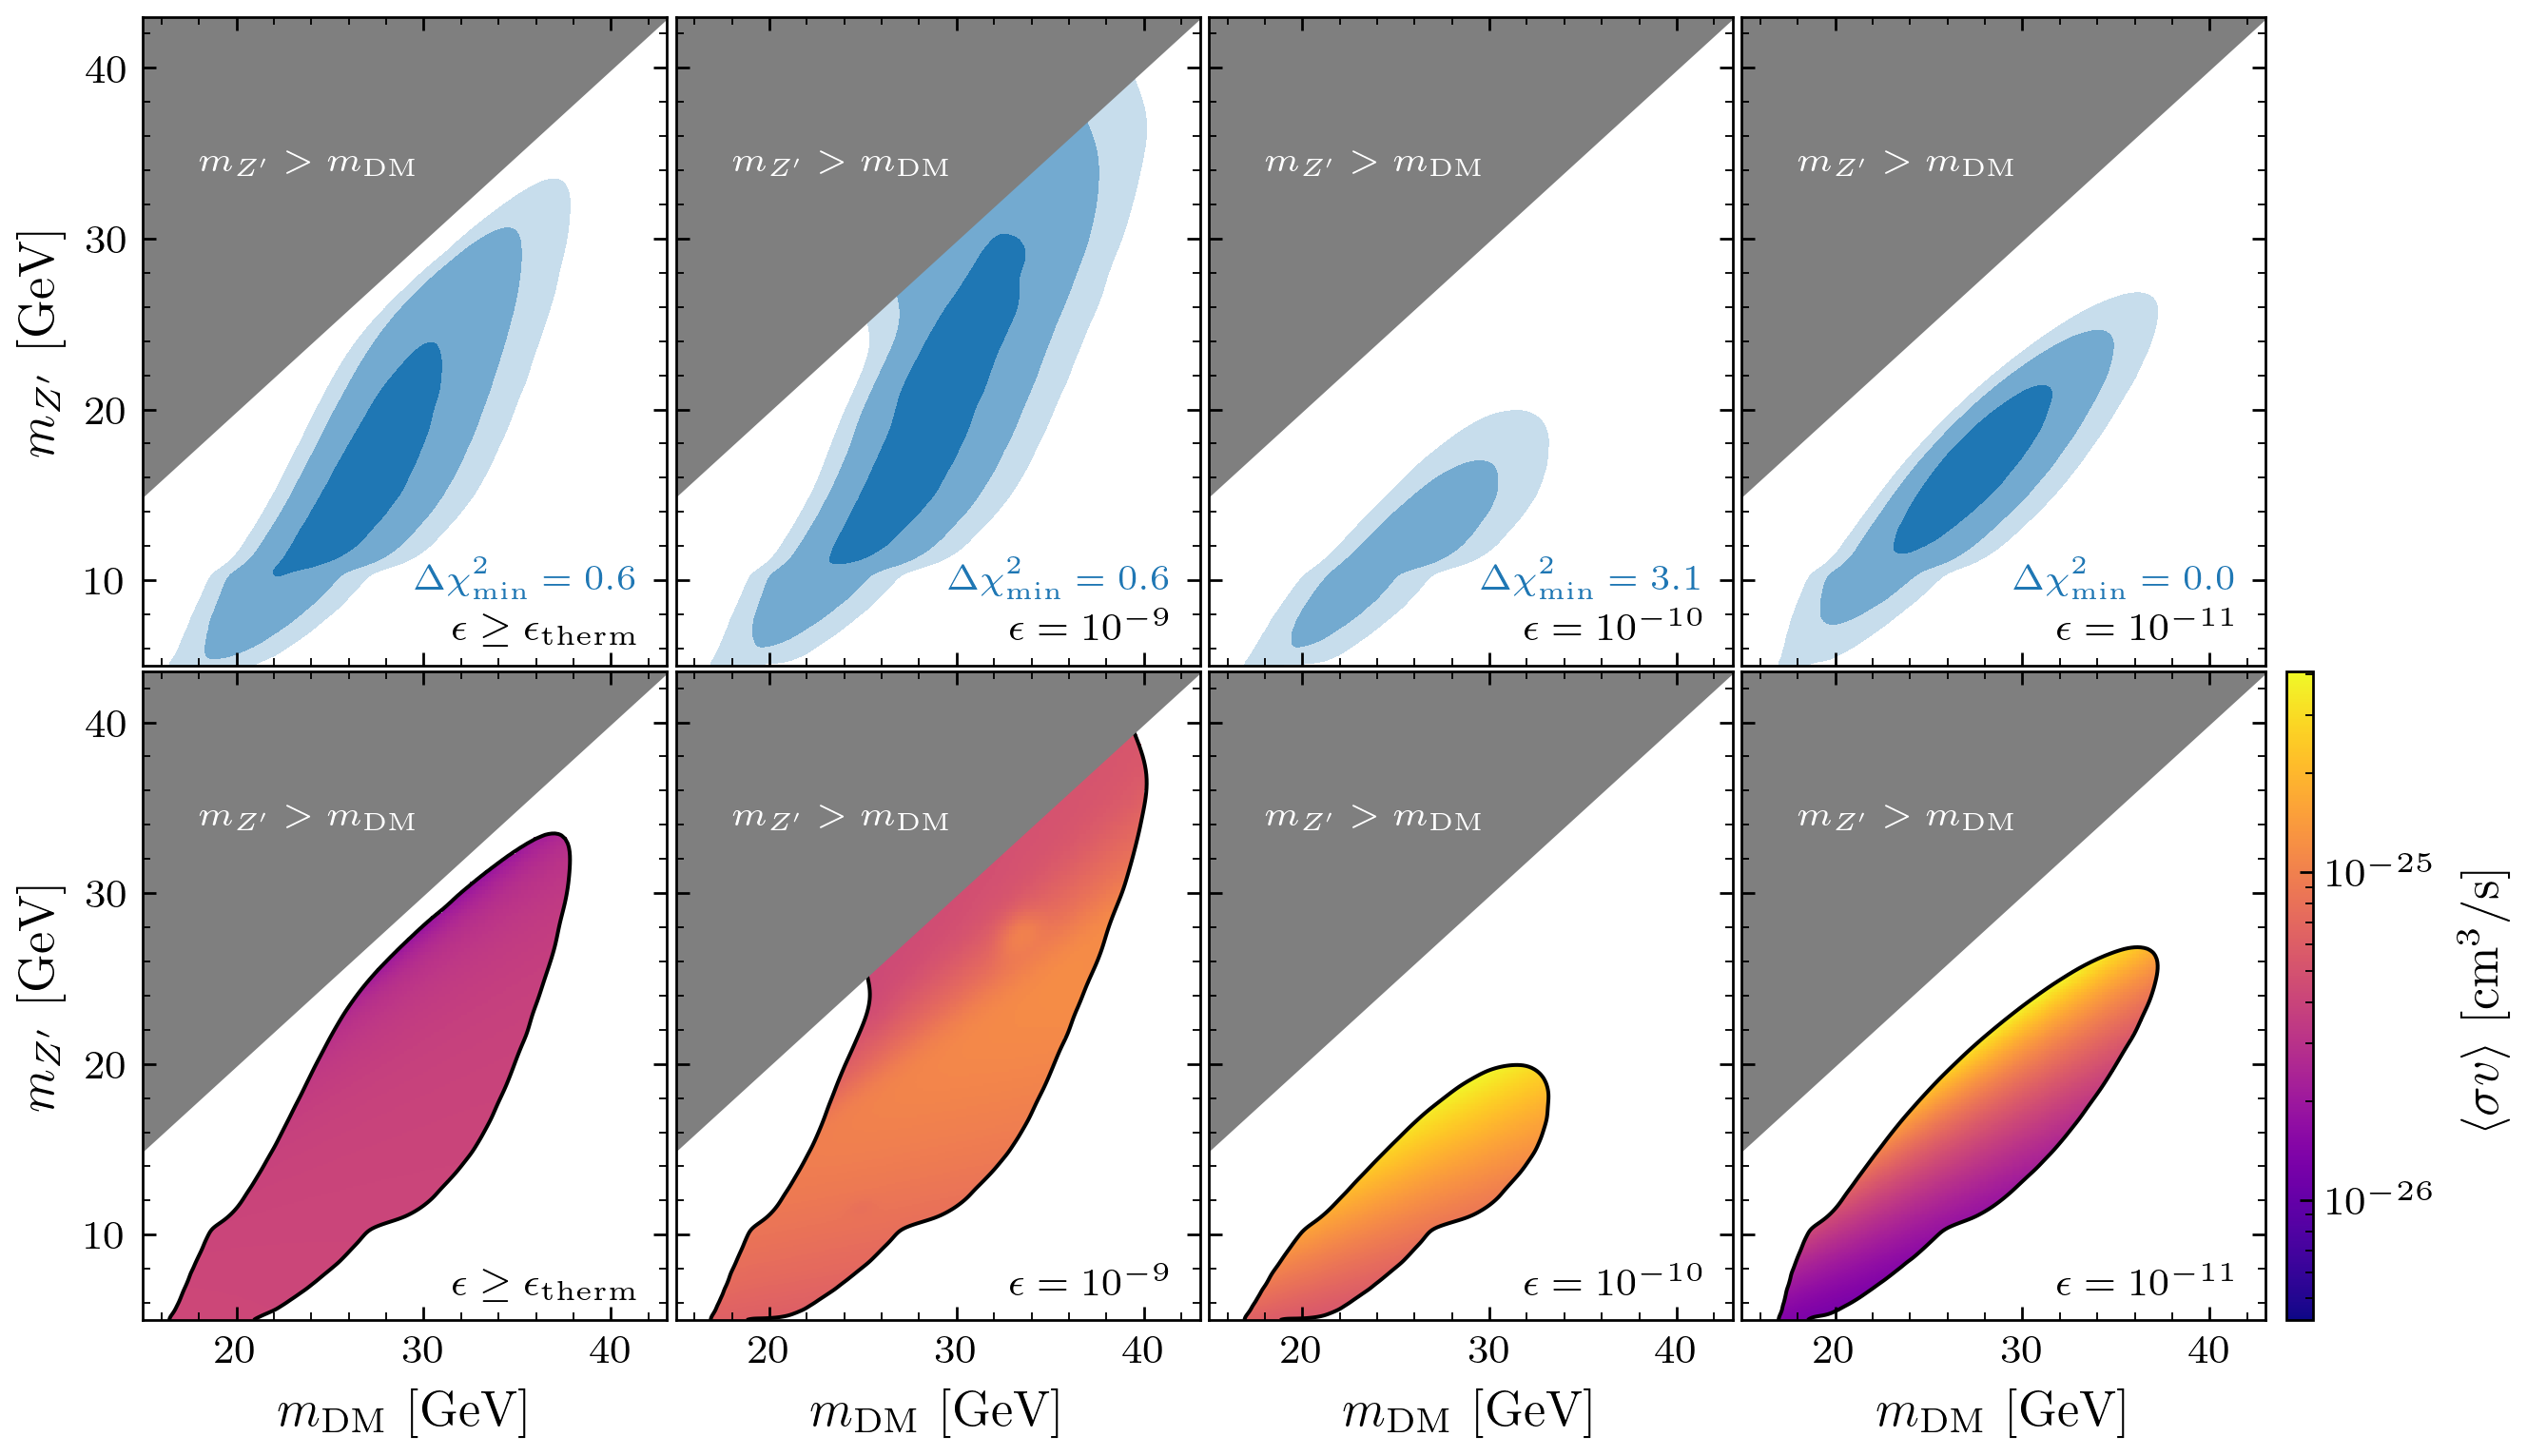

In [11]:
blP_fits=[fits_relic['blP'], fits_relic_eps['blP'][1e-9], fits_relic_eps['blP'][1e-10], fits_relic_eps['blP'][1e-11]]
cs1 = color_shades('tab:blue', 3)
eps_tex= [r'$\epsilon\geq \epsilon_{\rm therm}$',
          r'$\epsilon=10^{-9}$',
          r'$\epsilon=10^{-10}$',
          r'$\epsilon=10^{-11}$'
         ]
fig= plt.figure(figsize=(8, 8/(_GOLDEN_RATIO_)))
mDMs = np.linspace(5, 80, 100)
gs = GridSpec(40, 40, figure=fig)  # 7 rows and 7 columns for the triangle plot
ax1= fig.add_subplot(gs[:20, :10])
ax2= fig.add_subplot(gs[:20,10:20])
ax3= fig.add_subplot(gs[:20,20:30])
ax4= fig.add_subplot(gs[:20,30:])
ax12= fig.add_subplot(gs[20:, :10])
ax22= fig.add_subplot(gs[20:,10:20])
ax32= fig.add_subplot(gs[20:,20:30])
ax42= fig.add_subplot(gs[20:,30:])
axs=[ax1,ax2,ax3,ax4]
axs2=[ax12,ax22,ax32,ax42]
# relic <sigma v> inside each panel's 99% c.l. region; one colour scale, fixed across the vP, bP, blP figures
CLs = [relic_mX_mY_smooth_contours(fit, SIGMA=3) for fit in blP_fits]
log_svs = []
for fit, CL in zip(blP_fits, CLs):
    fin = np.isfinite(fit['dchi2_profiled'])     # the points CL was built from, so the same mesh
    log_sv = smoothed_field(fit['mX'][fin], fit['mY'][fin], np.log10(fit['sigmav_relic'][fin]),
                            sigma=3, rezero=False)[2]
    log_svs.append(np.where(CL[2] <= LVs[3], log_sv, np.nan))
for i in trange(len(axs)):
    axs[i].set_xlim(15,43)
    axs[i].set_xticks([20,30,40])
    axs[i].set_xticklabels([])
    axs2[i].set_xlim(15,43)
    axs2[i].set_xticks([20,30,40])
    axs[i].set_ylim(5, 43)
    axs[i].set_yticks([10,20,30,40])
    axs2[i].set_ylim(5, 43)
    axs2[i].set_yticks([10,20,30,40])
    if i!=0:
        axs[i].set_yticklabels([])
        axs2[i].set_yticklabels([])
    CL1=CLs[i]
    axs[i].contourf(CL1[0],CL1[1],CL1[2], levels=LVs, colors=cs1, zorder=1.5)
    cf_sv = axs2[i].pcolormesh(CL1[0],CL1[1],10**log_svs[i], cmap='plasma', shading='auto', zorder=1.5,
                               norm=mcolors.LogNorm(vmin=4.3e-27, vmax=4.1e-25),  # min / max over the vP, bP, blP 99% regions
                               rasterized=True)
    axs2[i].contour(CL1[0],CL1[1],CL1[2], levels=[LVs[3]], colors='k', linewidths=0.8, zorder=1.6)
    axs[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs2[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs[i].text(portal_axes_info['blP']['mxlims'][0]+(portal_axes_info['blP']['mxlims'][1]-portal_axes_info['blP']['mxlims'][0])/8,
          portal_axes_info['blP']['mxlims'][0]+(portal_axes_info['blP']['mxlims'][1]-portal_axes_info['blP']['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs2[i].text(portal_axes_info['blP']['mxlims'][0]+(portal_axes_info['blP']['mxlims'][1]-portal_axes_info['blP']['mxlims'][0])/8,
          portal_axes_info['blP']['mxlims'][0]+(portal_axes_info['blP']['mxlims'][1]-portal_axes_info['blP']['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs[i].text(41.5,6.5,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs2[i].text(41.5,6.5,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs[i].text(41.5,9.5, rf"$\Delta \chi^2_{{\rm min}}={np.nanmin(blP_fits[i]['dchi2_profiled']):.1f}$",  color=cs1[0], fontsize=mpl.rcParams['legend.fontsize'], ha='right')
    axs2[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
ax1.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
ax12.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
cbar = fig.colorbar(cf_sv, cax=ax42.inset_axes([1.04, 0.0, 0.05, 1.0]),
                    label=r"$\langle\sigma v\rangle\,\,[{\rm cm}^3/{\rm s}]$")
cbar.set_ticks([1e-26, 1e-25])                                                   # labelled decades
cbar.ax.yaxis.set_minor_locator(mpl.ticker.LogLocator(subs=np.arange(2, 10)))   # 2..9 x 10^n
cbar.ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
#ax2.text(32,45,r"$B-L$ Portal "+ rf"($\chi^2_{{\rm min}}={float(fits['blP']['chi2'][fits['blP']['k_best']]):.1f}$)",  fontsize=mpl.rcParams['axes.labelsize'], ha='left')
plt.savefig("../paper_figs/GCE_fits_blP_secluded_v0.png")
plt.savefig("../paper_figs/GCE_fits_blP_secluded_v0.pdf")
print(float(fits['blP']['chi2'][fits['blP']['k_best']]))
plt.show()
plt.close()

/tmp/ipykernel_3588566/4198848958.py:25: RuntimeWarning: divide by zero encountered in log10
  log_sv = smoothed_field(fit['mX'][fin], fit['mY'][fin], np.log10(fit['sigmav_relic'][fin]),


/home/gab/Desktop/Cosmo_Codes/cosmo_env/lib/python3.9/site-packages/matplotlib/tri/_triinterpolate.py:277: RuntimeWarning: invalid value encountered in add
  return (self._plane_coefficients[tri_index, 0]*x +


  0%|          | 0/4 [00:00<?, ?it/s]

 25%|██▌       | 1/4 [00:00<00:01,  1.78it/s]

 75%|███████▌  | 3/4 [00:00<00:00,  5.22it/s]

100%|██████████| 4/4 [00:00<00:00,  5.32it/s]

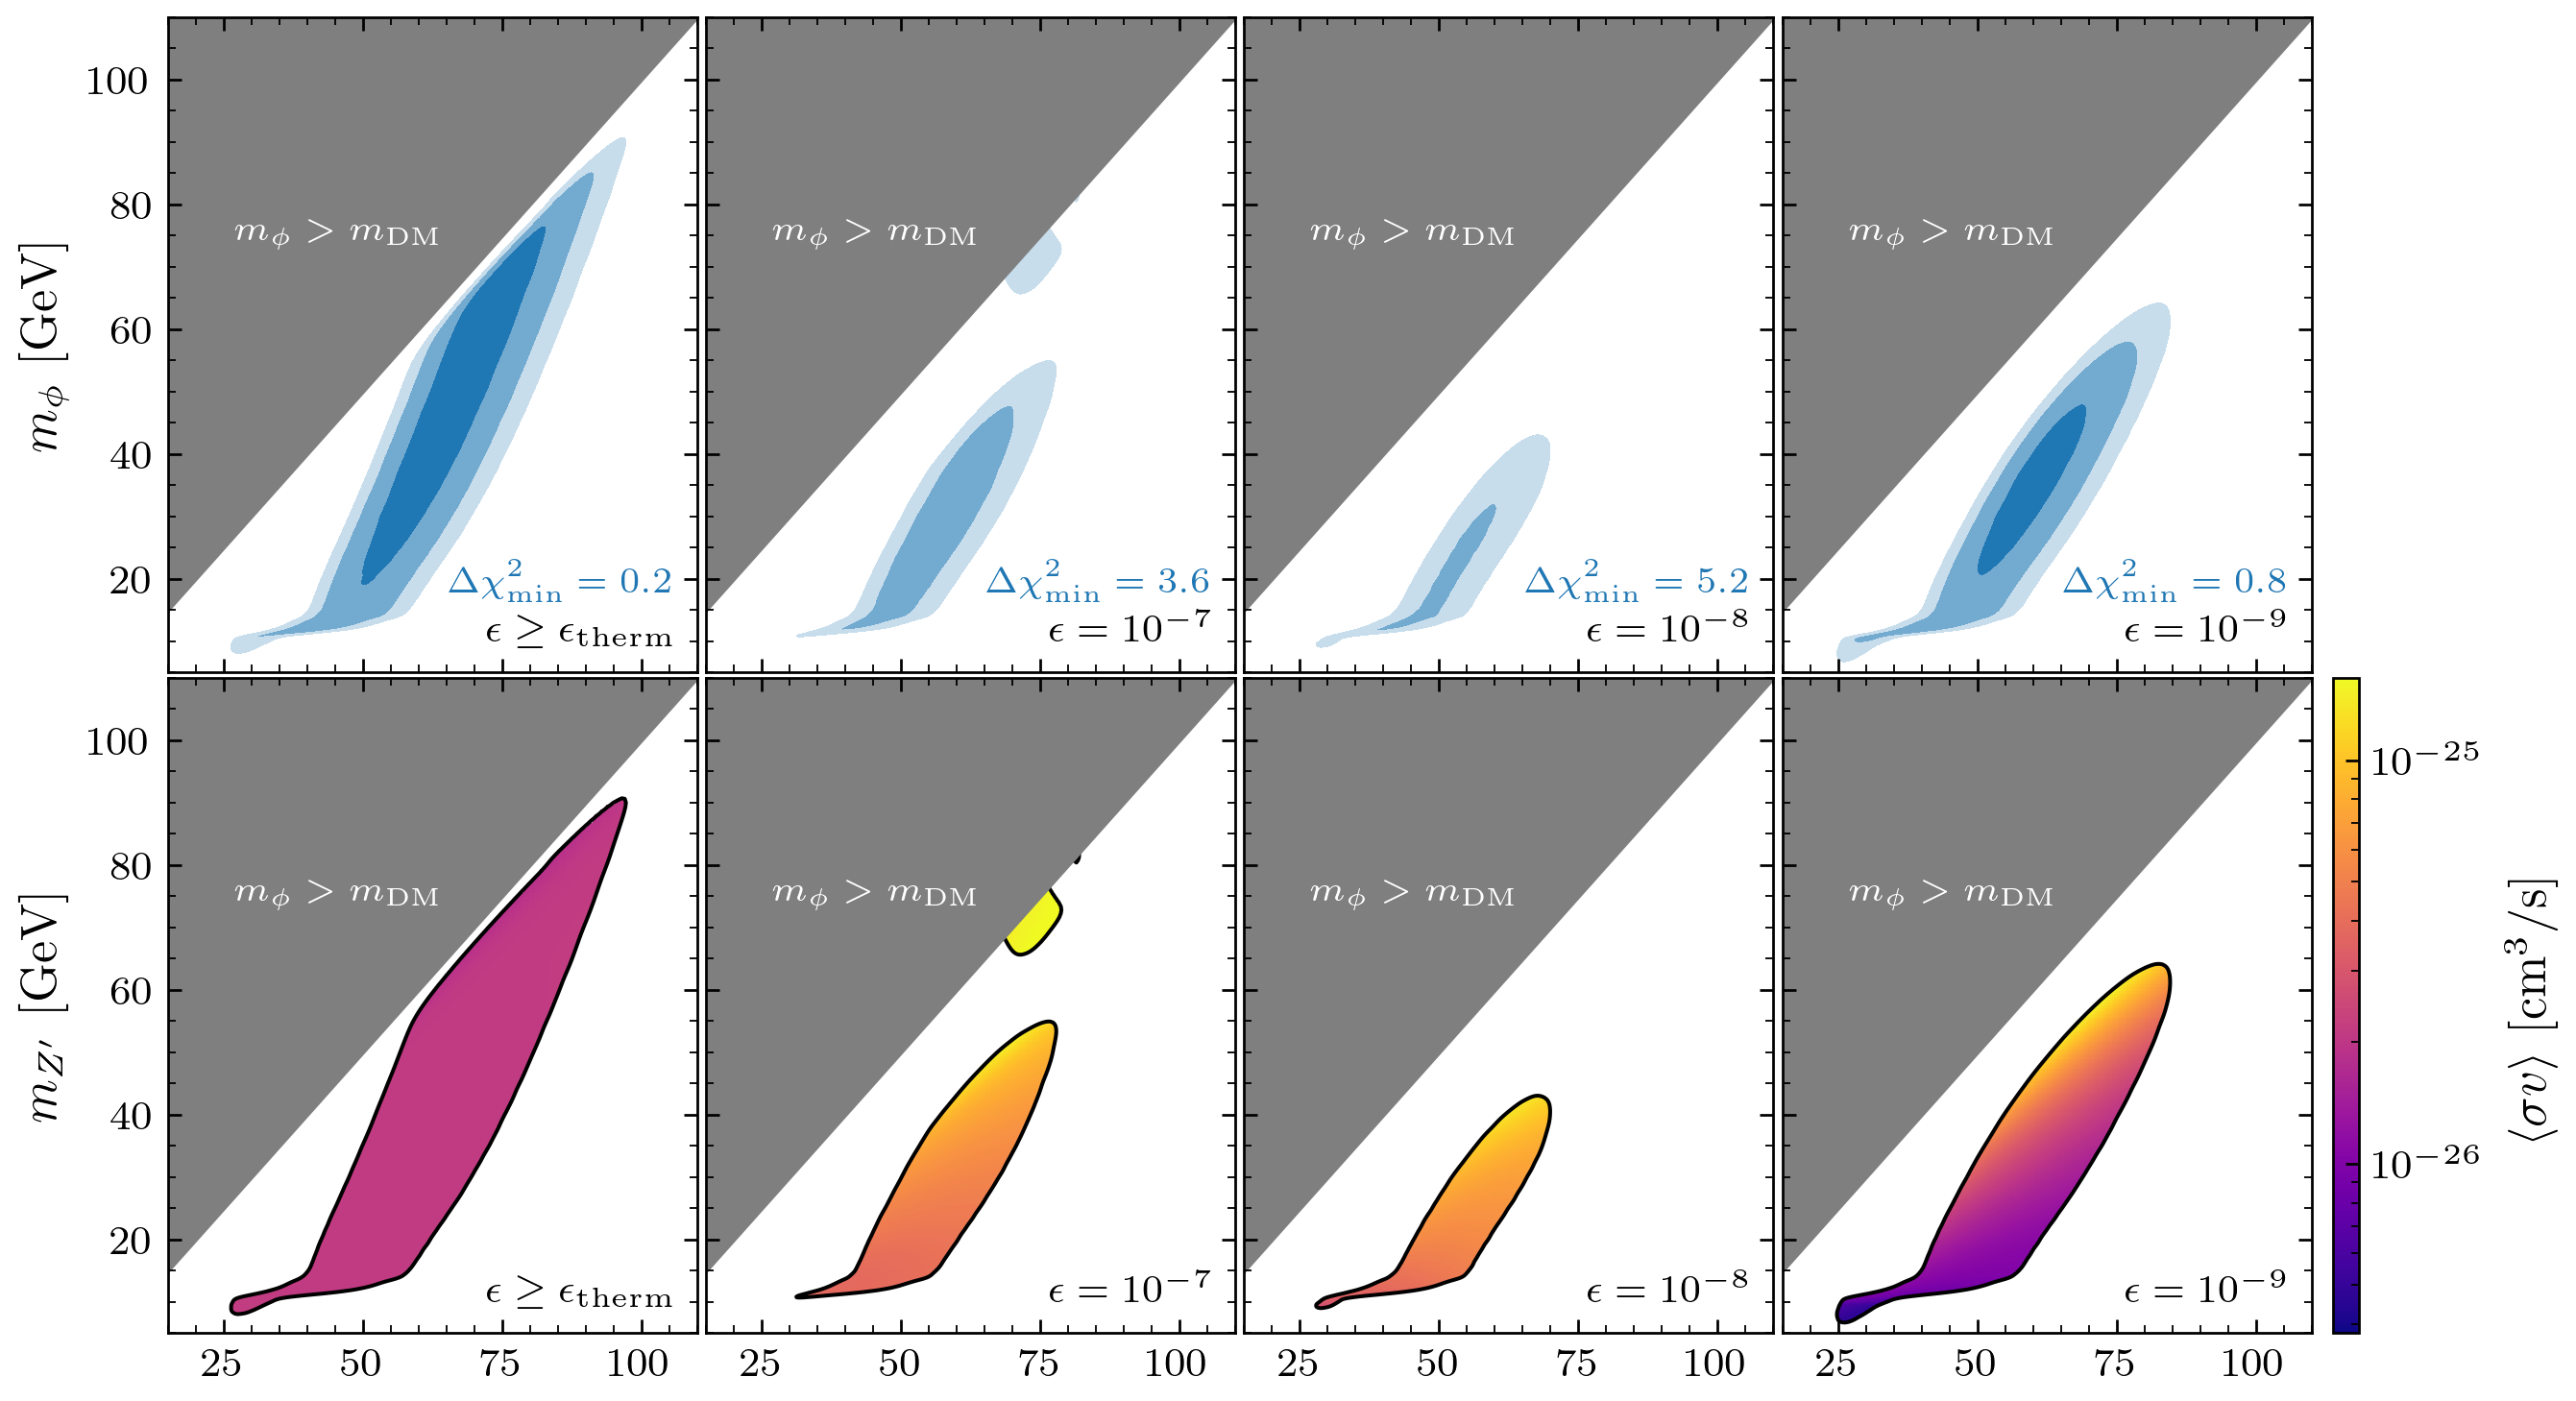

In [12]:
hP_fits=[fits_relic['hP'], fits_relic_eps['hP'][1e-7], fits_relic_eps['hP'][1e-8], fits_relic_eps['hP'][1e-9]]
cs1 = color_shades('tab:blue', 3)
eps_tex= [r'$\epsilon\geq \epsilon_{\rm therm}$',
          r'$\epsilon=10^{-7}$',
          r'$\epsilon=10^{-8}$',
          r'$\epsilon=10^{-9}$'
         ]
fig= plt.figure(figsize=(8, 8/(_GOLDEN_RATIO_)))
mDMs = np.linspace(5, 130, 100)
gs = GridSpec(40, 40, figure=fig)  # 7 rows and 7 columns for the triangle plot
ax1= fig.add_subplot(gs[:20, :10])
ax2= fig.add_subplot(gs[:20,10:20])
ax3= fig.add_subplot(gs[:20,20:30])
ax4= fig.add_subplot(gs[:20,30:])
ax12= fig.add_subplot(gs[20:, :10])
ax22= fig.add_subplot(gs[20:,10:20])
ax32= fig.add_subplot(gs[20:,20:30])
ax42= fig.add_subplot(gs[20:,30:])
axs=[ax1,ax2,ax3,ax4]
axs2=[ax12,ax22,ax32,ax42]
CLs = [relic_mX_mY_smooth_contours(fit) for fit in hP_fits]
log_svs = []
for fit, CL in zip(hP_fits, CLs):
    fin = np.isfinite(fit['dchi2_profiled'])     # the points CL was built from, so the same mesh
    log_sv = smoothed_field(fit['mX'][fin], fit['mY'][fin], np.log10(fit['sigmav_relic'][fin]),
                            sigma=3, rezero=False)[2]
    log_svs.append(np.where(CL[2] <= LVs[3], log_sv, np.nan))

for i in trange(len(axs)):
    axs[i].set_xlim( portal_axes_info['hP']['mxlims'][0], portal_axes_info['hP']['mxlims'][1])
    axs2[i].set_xlim( portal_axes_info['hP']['mxlims'][0], portal_axes_info['hP']['mxlims'][1])
    axs[i].set_xticklabels([])
    axs[i].set_ylim( portal_axes_info['hP']['mylims'][0], portal_axes_info['hP']['mylims'][1])
    axs2[i].set_ylim( portal_axes_info['hP']['mylims'][0], portal_axes_info['hP']['mylims'][1])
    if i!=0:
        axs[i].set_yticklabels([])
        axs2[i].set_yticklabels([])
    CL1=CLs[i]
    axs[i].contourf(CL1[0],CL1[1],CL1[2], levels=LVs, colors=cs1, zorder=1.5)
    cf_sv = axs2[i].pcolormesh(CL1[0],CL1[1],10**log_svs[i], cmap='plasma', shading='auto', zorder=1.5,
                               norm=mcolors.LogNorm(vmin=3.8e-27, vmax=1.6e-25),  # min / max over the vP, bP, blP 99% regions
                               rasterized=True)
    axs2[i].contour(CL1[0],CL1[1],CL1[2], levels=[LVs[3]], colors='k', linewidths=0.8, zorder=1.6)
    axs[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs2[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    axs[i].text(portal_axes_info['hP']['mxlims'][0]+(portal_axes_info['hP']['mxlims'][1]-portal_axes_info['hP']['mxlims'][0])/8,
          portal_axes_info['hP']['mxlims'][0]+(portal_axes_info['hP']['mxlims'][1]-portal_axes_info['hP']['mxlims'][0])/1.6,
          r"$m_{\phi}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs2[i].text(portal_axes_info['hP']['mxlims'][0]+(portal_axes_info['hP']['mxlims'][1]-portal_axes_info['hP']['mxlims'][0])/8,
          portal_axes_info['hP']['mxlims'][0]+(portal_axes_info['hP']['mxlims'][1]-portal_axes_info['hP']['mxlims'][0])/1.6,
          r"$m_{\phi}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs[i].text(106,10,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs2[i].text(106,10,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs[i].text(106,18, rf"$\Delta \chi^2_{{\rm min}}={np.nanmin(hP_fits[i]['dchi2_profiled']):.1f}$",  color=cs1[0], fontsize=mpl.rcParams['legend.fontsize'], ha='right')
    axs[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
ax1.set_ylabel(r"$m_{\phi}\,\,[{\rm GeV}]$")
ax12.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
cbar = fig.colorbar(cf_sv, cax=ax42.inset_axes([1.04, 0.0, 0.05, 1.0]),
                    label=r"$\langle\sigma v\rangle\,\,[{\rm cm}^3/{\rm s}]$")
cbar.set_ticks([1e-26, 1e-25])                                                   # labelled decades
cbar.ax.yaxis.set_minor_locator(mpl.ticker.LogLocator(subs=np.arange(2, 10)))   # 2..9 x 10^n
cbar.ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

#ax2.text(42,75, r"Higgs Portal "+ rf"($\chi^2_{{\rm min}}={float(fits['hP']['chi2'][fits['hP']['k_best']]):.1f}$)",  fontsize=mpl.rcParams['axes.labelsize'], ha='left')
with mpl.rc_context({'pdf.compression': 0}):
    plt.savefig("../paper_figs/GCE_fits_hP_secluded_v0.pdf")
plt.savefig("../paper_figs/GCE_fits_hP_secluded_v0.png")
plt.show()
plt.close()

## Dependence on the initial temperature ratio
The hypercharge-portal relic region for $\xi_0 = T_D/T_{\rm SM} = 0.5,\ 1,\ 2.5$ at $\epsilon = 10^{-9}, 10^{-10}, 10^{-11}$.

  0%|          | 0/3 [00:00<?, ?it/s]

 33%|███▎      | 1/3 [00:01<00:02,  1.28s/it]

 67%|██████▋   | 2/3 [00:02<00:01,  1.17s/it]

100%|██████████| 3/3 [00:04<00:00,  1.49s/it]

100%|██████████| 3/3 [00:04<00:00,  1.41s/it]

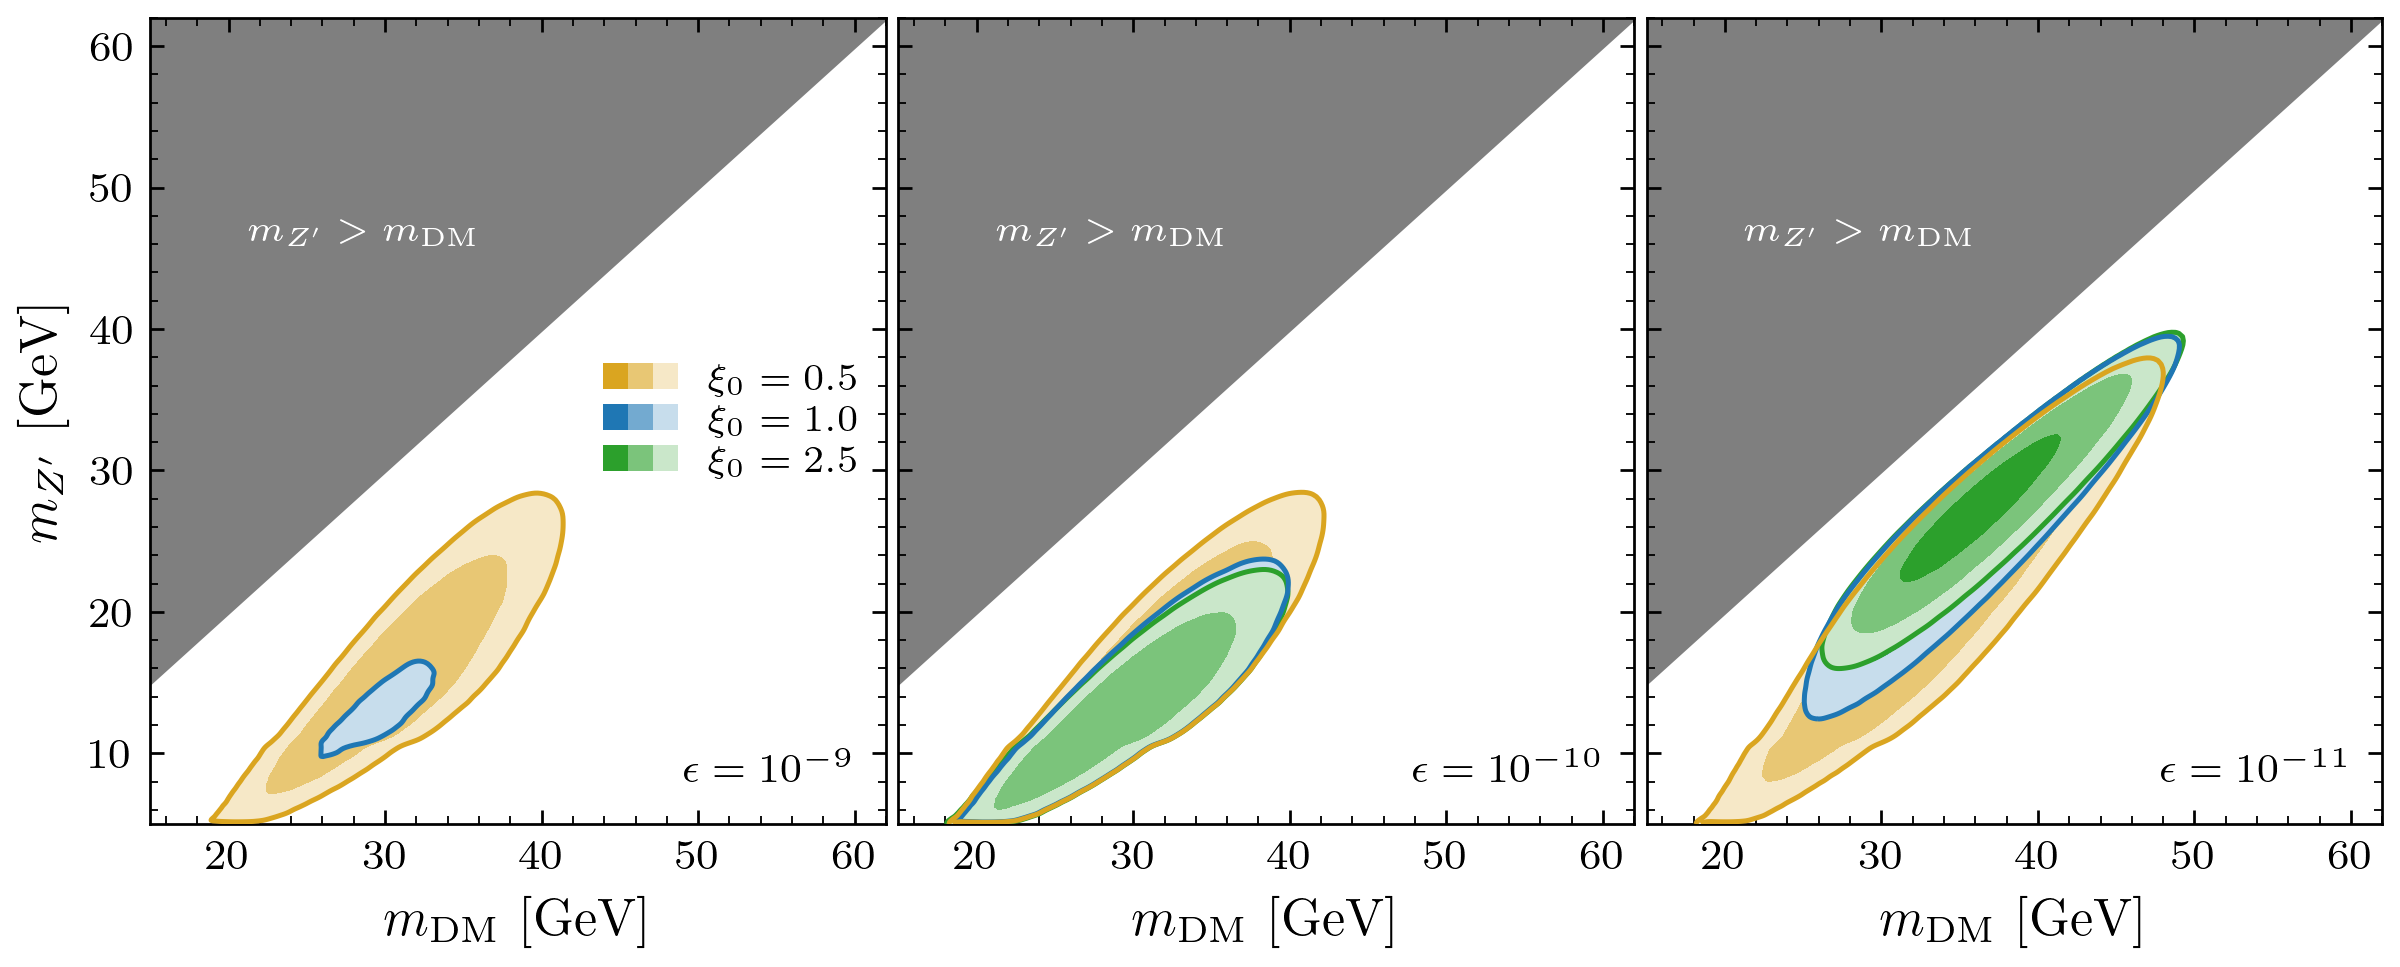

In [13]:
# ---- vP relic region vs the initial temperature ratio xi_ini = T_D/T_SM ----
# the fits_relic_eps['vP'] chain on the xi_ini = 0.5 and 2.5 grids; xi_ini = 1 is
# fits_relic_eps['vP'] itself.  rho_odot profiled, 99% c.l. region per xi_ini.
XI_INI = (0.5, 1.0, 2.5)
EPS_XI = (1e-9, 1e-10, 1e-11)        # panel order
vP_xi_fits = {0.5: {eps: sv_relic_at_eps('vP', eps, xi_ini=0.5) for eps in EPS_XI},
              1.0: {eps: fits_relic_eps['vP'][eps] for eps in EPS_XI},
              2.5: {eps: sv_relic_at_eps('vP', eps, xi_ini=2.5) for eps in EPS_XI}}
for relic in vP_xi_fits[0.5].values():
    relic['dchi2_fixed_halo'], relic['dchi2_profiled'] = sv_relic_region(relic, fits['vP'])
for relic in vP_xi_fits[2.5].values():
    relic['dchi2_fixed_halo'], relic['dchi2_profiled'] = sv_relic_region(relic, fits['vP'])

css = [ color_shades('goldenrod', 3),color_shades('tab:blue', 3), color_shades('tab:green', 3)]
eps_tex = [r'$\epsilon=10^{-9}$',
           r'$\epsilon=10^{-10}$',
           r'$\epsilon=10^{-11}$'
          ]
fig= plt.figure(figsize=(8, 8/(1.7*_GOLDEN_RATIO_)))
mDMs = np.linspace(10, 70, 50)
gs = GridSpec(40, 30, figure=fig)
ax1 = fig.add_subplot(gs[:, :10])
ax2 = fig.add_subplot(gs[:, 10:20])
ax3 = fig.add_subplot(gs[:, 20:30])
axs = [ax1, ax2, ax3]
for i in trange(len(axs)):
    axs[i].set_xlim(15,62)
    axs[i].set_xticks([20,30,40,50,60])
    axs[i].set_ylim(5, 62)
    axs[i].set_yticks([10,20,30,40,50,60])
    if i!=0:
        axs[i].set_yticklabels([])
    for k, xi_ini in enumerate(XI_INI):
        CL1 = relic_mX_mY_smooth_contours(vP_xi_fits[xi_ini][EPS_XI[i]], SIGMA=2)
        #axs[i].contourf(CL1[0], CL1[1], CL1[2], levels=[0, LVs[3]], colors=[css[k][1]], zorder=3)
        axs[i].contourf(CL1[0], CL1[1], CL1[2], levels=LVs, colors=css[k], zorder=3)
        axs[i].contour(CL1[0], CL1[1], CL1[2], levels=[LVs[3]], colors=css[k][0],
                       linewidths=1, zorder=3.3 - 0.1 * k)
    axs[i].fill_between(mDMs, mDMs, np.ones(len(mDMs)) * 1e4, zorder=2, color='tab:grey')
    axs[i].text(portal_axes_info['vP']['mxlims'][0]+(portal_axes_info['vP']['mxlims'][1]-portal_axes_info['vP']['mxlims'][0])/8,
          portal_axes_info['vP']['mxlims'][0]+(portal_axes_info['vP']['mxlims'][1]-portal_axes_info['vP']['mxlims'][0])/1.6,
          r"$m_{Z^\prime}>m_{\rm DM}$", color="white",  fontsize=mpl.rcParams['legend.fontsize'], ha='left')
    axs[i].text(60,8,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize']*1.1, ha='right')
    axs[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
ax1.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
ax1.legend(
    handles=[(Patch(facecolor=css[0][0]),Patch(facecolor=css[0][1]),Patch(facecolor=css[0][2])),
            (Patch(facecolor=css[1][0]),Patch(facecolor=css[1][1]),Patch(facecolor=css[1][2])),
            (Patch(facecolor=css[2][0]),Patch(facecolor=css[2][1]),Patch(facecolor=css[2][2]))],
    labels=[r'$\xi_0=0.5$', r'$\xi_0=1.0$',r'$\xi_0=2.5$'],
    loc='center right',
    fontsize=mpl.rcParams['legend.fontsize'],
    handler_map={tuple: mpl.legend_handler.HandlerTuple(ndivide=None, pad=0.0)},
    )

plt.savefig("../paper_figs/GCE_fits_vP_xi_ini_v0.png")
plt.savefig("../paper_figs/GCE_fits_vP_xi_ini_v0.pdf")
plt.show()
plt.close()

## Best-fit spectra
Each portal's best-fit $E^2\, d\Phi/dE$ over the measured GCE spectrum (68/95/99% bands). With $\langle\sigma v\rangle$ free, neither the curves nor the bands depend on $\rho_\odot$.

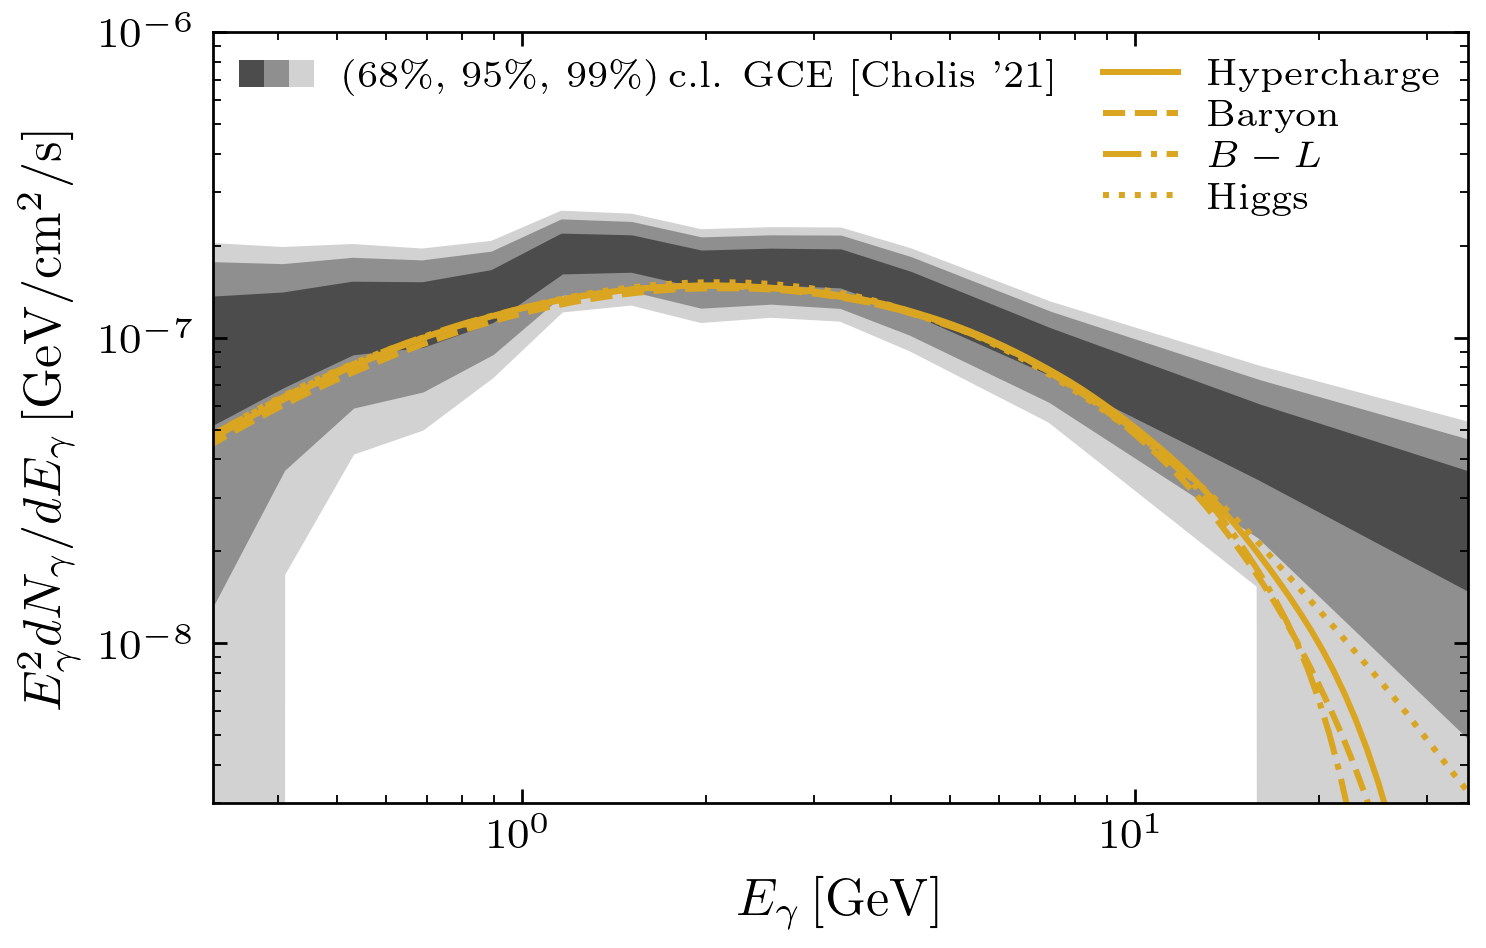

In [14]:
from GCE.source.gce_data import EBIN_CTR
from GCE.source.spectrum import cascade_flux, default_ebins
from GCE.source.halo import j_factor
from hidden_sector_DM.HiddenSectorDM import VectorPortal, BaryonPortal, HiggsPortal,BLPortal  

# ---- the vP best fit over the measured spectrum [Cholis '21] ---------------
# sigmav was profiled against templates built at HALO_2112, so sigmav x Jbar(HALO_2112)
# is the fitted amplitude itself: neither the curve nor the data band depends on rho_odot
_, dOmega = j_factor(return_solid_angle=True, **{**HALO_2112, "roi": REGION})
C = np.linalg.inv(Cinv)
draws = np.random.default_rng(0).multivariate_normal(phi, C, size=20000)
lo68, hi68 = np.percentile(draws, [16, 84], axis=0)
lo95, hi95 = np.percentile(draws, [2.5, 97.5], axis=0)
lo99, hi99 = np.percentile(draws, [0.5, 99.5], axis=0)
cs_data = color_shades((0.3, 0.3, 0.3) , 3)
plt.fill_between(EBIN_CTR, lo99*dOmega, hi99*dOmega, color=cs_data[2], alpha=1)
plt.fill_between(EBIN_CTR, lo95*dOmega, hi95*dOmega, color=cs_data[1], alpha=1)
plt.fill_between(EBIN_CTR, lo68*dOmega, hi68*dOmega, color=cs_data[0], alpha=1)
lss=['-','--','-.',':']
portal_names=['Hypercharge','Baryon', r'$B-L$', r'Higgs']
k_best_vP = fits[portals[0]]['k_best']
k_best_bP = fits[portals[1]]['k_best']
k_best_blP = fits[portals[2]]['k_best']
k_best_hP = fits[portals[3]]['k_best']
mod_hP = HiggsPortal(mX=float(MX_GRID_hP[k_best_hP]), mY=float(MY_GRID_hP[k_best_hP]), gX=2, gY=1, lam=1e-2)
mod_vP = VectorPortal(mX=float(MX_GRID[k_best_vP]), mY=float(MY_GRID[k_best_vP]), gX=2, gY=3, alphaX=1e-2)
mod_bP = BaryonPortal(mX=float(MX_GRID[k_best_bP]), mY=float(MY_GRID[k_best_bP]), gX=2, gY=3, alphaX=1e-2)
mod_blP = BLPortal(mX=float(MX_GRID[k_best_blP]), mY=float(MY_GRID[k_best_blP]), gX=2, gY=3, alphaX=1e-2)

mods=[mod_vP, mod_bP, mod_blP, mod_hP]
k_bests=[k_best_vP, k_best_bP, k_best_blP, k_best_hP]
for i in range(len(mods)):
    E_best, dPhidE_best = cascade_flux(mods[i], default_ebins(mods[i].mX, n_bins=180),
                                   sigmav=fits[portals[i]]['sigmav'][k_bests[i]],
                                   n_events=400_000, seed=DEFAULT_SEED)
    dPhidlnE_best = gaussian_filter1d(E_best * dPhidE_best, 2, mode='nearest')
    plt.plot(E_best, E_best*dPhidlnE_best*dOmega, c='goldenrod', lw=1.2, ls=lss[i],
         label=portal_names[i])
leg1 = plt.legend()
plt.legend(
    handles=[(Patch(facecolor=cs_data[0]), Patch(facecolor=cs_data[1]), Patch(facecolor=cs_data[2]))],
    labels=[r"$(68\%,\,95\%,\,99\%)\,$c.l. GCE [Cholis '21]"],
    loc=2,
    handler_map={tuple: mpl.legend_handler.HandlerTuple(ndivide=None, pad=0.0)},
    )
plt.gca().add_artist(leg1)
plt.yscale("log")
plt.xscale("log")
plt.ylim(3e-9, 1e-6)
plt.xlim(EBIN_CTR[0], EBIN_CTR[-1])
plt.ylabel(r"$E^2_\gamma dN_\gamma/dE_\gamma\,[{\rm GeV}/{\rm cm}^2/{\rm s}]$")
plt.xlabel(r"$E_\gamma\,[{\rm GeV}]$")
plt.savefig("../paper_figs/GCE_spec_v0.png")
plt.savefig("../paper_figs/GCE_spec_v0.pdf")
plt.show()
plt.close()